# 🏆 Decision Intelligence Capstone: Modelado Predictivo, Inferencia Causal y Sistemas de Decisión en Producción
**Cátedra:** Estadística Aplicada y Modelos de Regresión (EAyMR 2026)  
**Institución:** Pontificia Universidad Católica Argentina (UCA) — Facultad de Ingeniería y Ciencias Agrarias  
**Profesor Titular:** Prof. Ivan Gonzalo Vilaboa  
**Integrantes y Roles Scrum:**
- 👑 **Project Lead, Scrum Master & Econometría (Fases 1–2):** German Sittner
- ⚙ **Backend & Machine Learning Engineer (Fase 3):** Martín Peña
- 🧠 **Causal Inference & Causal ML Engineer (Fase 4):** Santiago Salvatore
- 🔍 **QA, Validation & UI/UX Deployment (Transversal & Fase 5):** Equipo EAyMR (Validación cruzada `pytest`)

---

## 📌 Base del Proyecto: Contrato de Datos y Partición Oficial
Todos los análisis de este proyecto se sustentan en el contrato unificado definido en `src/config.py` y generado por `src/data_pipeline.py` sobre el dataset real **HMEQ** ($N = 5.960$, 13 variables originales):
- **Target Primario ($Y$):** `BAD` ($1$ = Default/Moroso, $0$ = Cumplidor).
- **Target Continuo ($Y_{\text{cont}}$):** `LOAN` (monto de crédito solicitado).
- **Tratamiento Causal ($T$):** `TREATMENT` ($1$ = Consolidación de Deuda `DebtCon`, $0$ = Mejoras del Hogar `HomeImp`).
- **Factor ANOVA ($k \ge 3$):** `JOB` (6 categorías ocupacionales).
- **Mediador Post-Tratamiento ($M$):** `LOAN` (excluido del ajuste causal Backdoor/DML).
- **Partición Oficial:** `data/processed/train.csv` ($80\%$, $N = 4.768$) y `data/processed/test.csv` ($20\%$, $N = 1.192$), imputada sin fuga de datos (*No Data Leakage*).


In [1]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

from src.config import (
    DATA_RAW_PATH, TRAIN_PATH, TEST_PATH, TARGET_BINARY, TARGET_CONTINUOUS,
    TREATMENT_VAR, ANOVA_FACTOR, ANOVA_VARIABLE, NUMERICAL_FEATURES
)
from src.phase1_inference import (
    load_phase1_datasets, analyze_missing_mechanism, compute_multidimensional_eda,
    run_hypothesis_contrasts, run_anova_and_diagnostics
)
from src.phase2_econometrics import (
    load_phase2_splits, fit_ols_reference, audit_gauss_markov,
    detect_influential_points, compare_robust_regressors, calculate_vif,
    run_pca_no_leakage
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

df_raw, train_df = load_phase1_datasets()
test_df = pd.read_csv(TEST_PATH)
print(f"Dataset crudo: {df_raw.shape} | Train oficial: {train_df.shape} | Test oficial: {test_df.shape}")


Dataset crudo: (5960, 13) | Train oficial: (4768, 15) | Test oficial: (1192, 15)


---

## 🔬 FASE 1: Inferencia Estadística Clásica, Diagnósticos y ANOVA
*(Articulación directa con Unidades 1 y 2)*

### 1.1 Diagnóstico Matemático del Mecanismo de Pérdida de Datos (MCAR vs. MAR/MNAR)
Verificamos el patrón de omisión sobre el dataset original (`hmeq.csv`) mediante un modelo logit sobre la ausencia de `DEBTINC` ($21.26\%$ de nulos):
$$\text{logit}(P(\text{DEBTINC is missing})) = \beta_0 + \beta_1 \text{LOAN} + \beta_2 \text{VALUE} + \beta_3 \text{BAD}$$


In [2]:
missing_res = analyze_missing_mechanism(df_raw)
display(missing_res['missing_table'][missing_res['missing_table']['Nulos'] > 0])
print(missing_res['logit_debtinc_missing'].summary().tables[1])
print(f"¿Es MCAR?: {missing_res['is_mcar']} | Odds Ratio de omisión para BAD=1: {missing_res['odds_ratio_bad']:.2f}x")


,Nulos,Porcentaje (%)
DEBTINC,1267,21.2584
DEROG,708,11.8792
DELINQ,580,9.7315
MORTDUE,518,8.6913
YOJ,515,8.6409
NINQ,510,8.5570
CLAGE,308,5.1678
JOB,279,4.6812
REASON,252,4.2282
CLNO,222,3.7248


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.7563      0.091    -19.293      0.000      -1.935      -1.578
LOAN       -2.057e-05   4.14e-06     -4.968      0.000   -2.87e-05   -1.25e-05
VALUE      -6.018e-07   6.94e-07     -0.867      0.386   -1.96e-06    7.59e-07
BAD            2.7908      0.080     34.737      0.000       2.633       2.948
¿Es MCAR?: False | Odds Ratio de omisión para BAD=1: 16.29x


**Conclusión:** El coeficiente de `BAD` es $z = 34.74$ ($p < 10^{-16}$, $OR \approx 16.3$). Se rechaza formalmente el mecanismo MCAR a favor de **MAR/MNAR**. Por ello, en el pipeline oficial preservamos `DEBTINC_is_missing` e imputamos medianas aprendidas únicamente sobre Train.

---

### 1.2 EDA Multidimensional: Distribuciones KDE, Boxplots y Correlación Pearson vs. Spearman


,Variable,N,Media,Mediana,Desv_Est,Asimetria,Curtosis,IQR
0,LOAN,4768,18531.9002,16200.0000,11230.9063,2.0455,7.0805,12300.0000
1,MORTDUE,4768,72914.4629,65022.0000,42322.9613,1.9341,7.4318,40138.5000
2,VALUE,4768,101408.7388,89250.0000,56463.1914,3.0234,24.0681,52257.7500
3,YOJ,4768,8.7515,7.0000,7.2938,1.0836,0.7026,9.0000
4,DEROG,4768,0.2250,0.0000,0.7993,5.6600,41.8422,0.0000
5,DELINQ,4768,0.4115,0.0000,1.0997,4.3652,27.8486,0.0000
6,CLAGE,4768,179.1756,173.4954,83.8535,1.4980,9.5706,107.9811
7,NINQ,4768,1.1724,1.0000,1.6491,2.8006,11.4243,2.0000
8,CLNO,4768,21.2280,20.0000,10.0323,0.8209,1.4017,11.0000
9,DEBTINC,4768,33.9804,34.8024,7.4003,2.7958,67.8782,7.0902


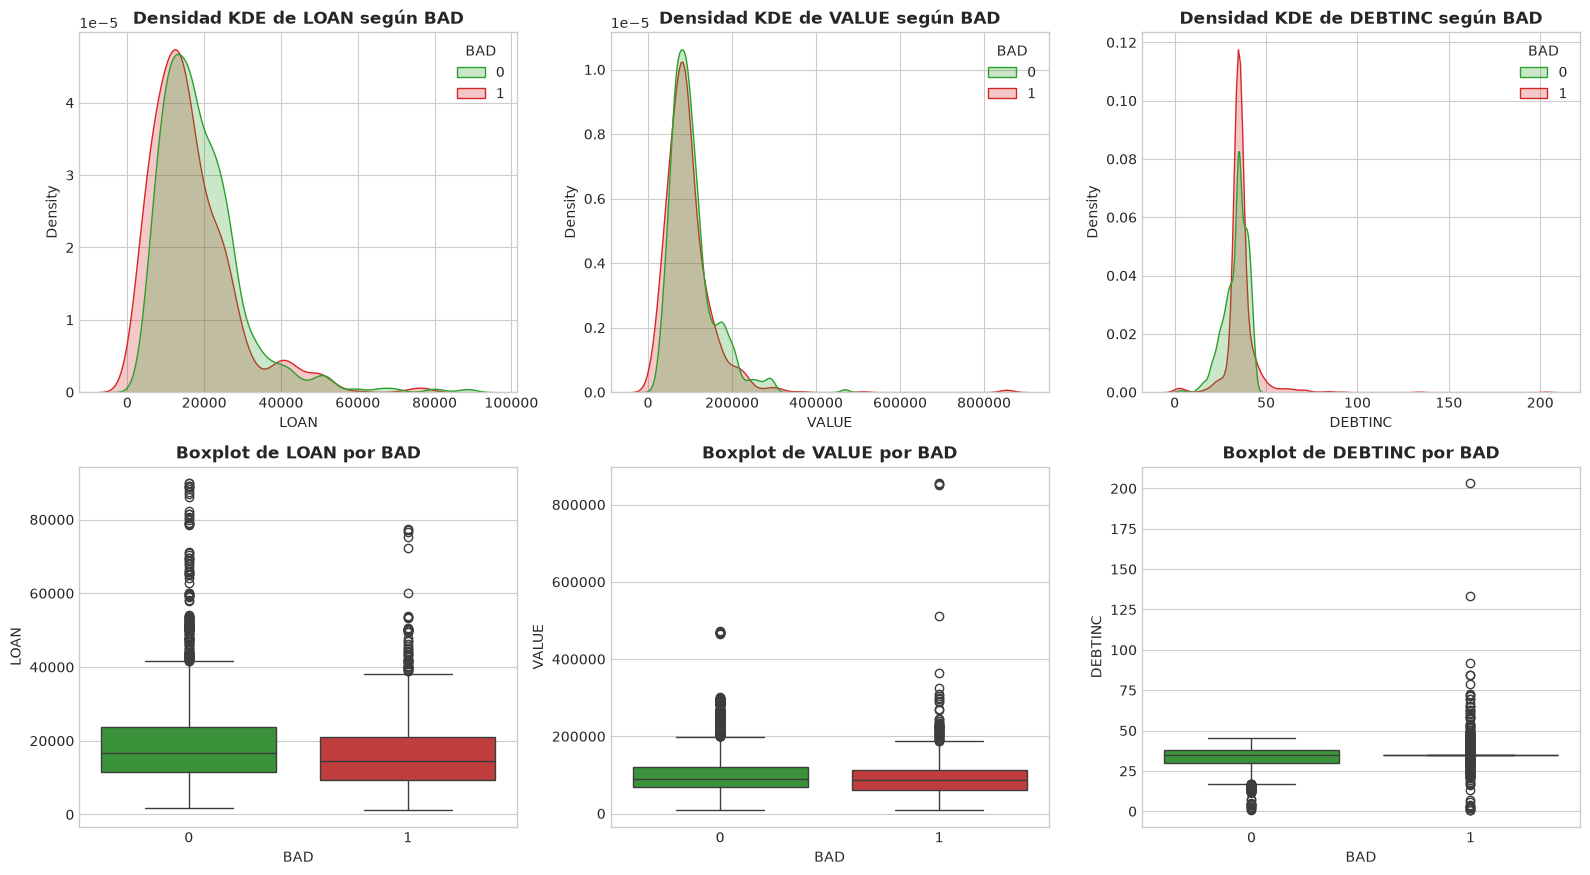

In [3]:
eda_res = compute_multidimensional_eda(train_df)
display(eda_res['descriptivos'])

# Visualización Multidimensional: KDE y Boxplots por BAD
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
vars_plot = ['LOAN', 'VALUE', 'DEBTINC']
for i, col in enumerate(vars_plot):
    sns.kdeplot(data=train_df, x=col, hue=TARGET_BINARY, fill=True, common_norm=False,
                palette={0: '#2ca02c', 1: '#d62728'}, ax=axes[0, i])
    axes[0, i].set_title(f'Densidad KDE de {col} según {TARGET_BINARY}', fontweight='bold')
    
    sns.boxplot(data=train_df, x=TARGET_BINARY, y=col, hue=TARGET_BINARY,
                palette={0: '#2ca02c', 1: '#d62728'}, legend=False, ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot de {col} por {TARGET_BINARY}', fontweight='bold')

plt.tight_layout()
plt.show()


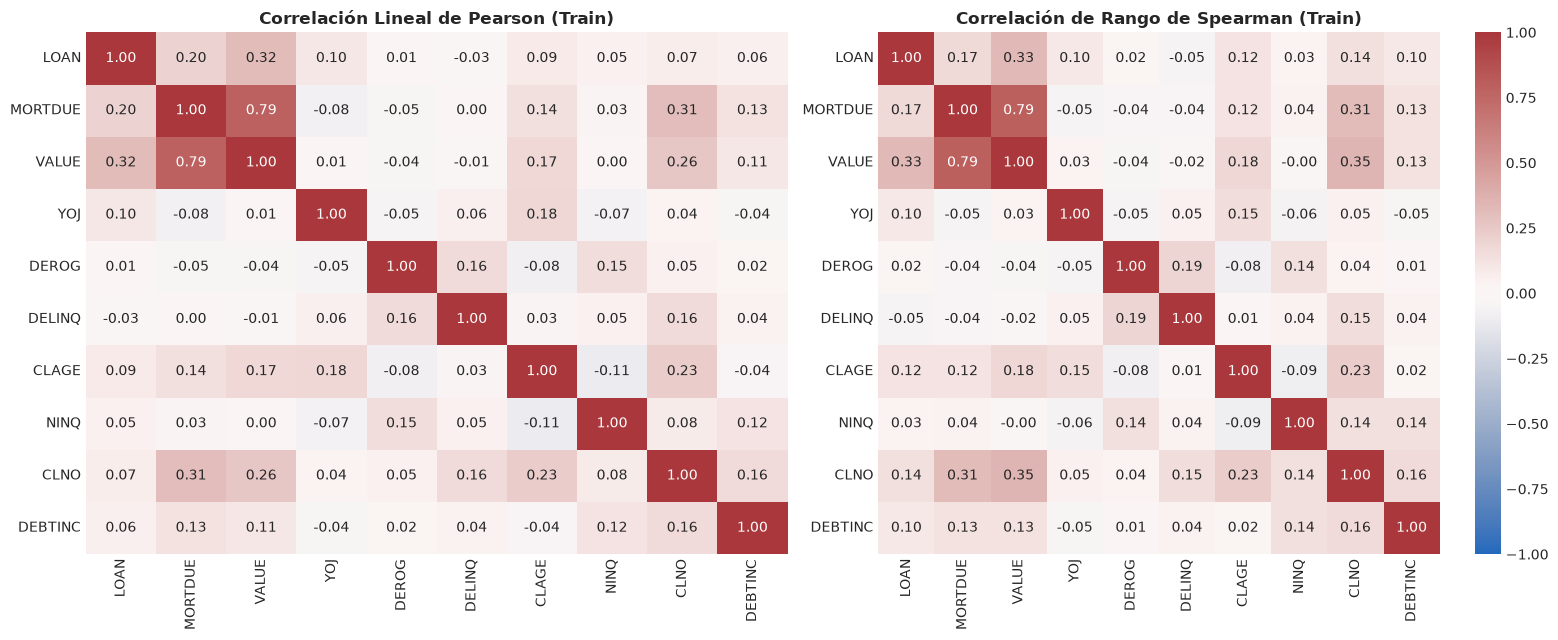

In [4]:
# Matrices de Correlación Paramétrica (Pearson) vs No Paramétrica (Spearman)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(eda_res['corr_pearson'], annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title('Correlación Lineal de Pearson (Train)', fontsize=12, fontweight='bold')

sns.heatmap(eda_res['corr_spearman'], annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Correlación de Rango de Spearman (Train)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 1.3 Contrastes Formales de Hipótesis ($H_0$ frente a $H_1$, $\alpha = 0.05$)
1. **Contraste 1:** ¿El monto solicitado (`LOAN`) difiere entre cumplidores (`BAD=0`) y morosos (`BAD=1`)? ($H_0: \mu_0 = \mu_1$ vs $H_1: \mu_0 \neq \mu_1$).
2. **Contraste 2:** ¿El ratio deuda/ingreso (`DEBTINC`) es mayor en consolidación de pasivos (`DebtCon`) frente a reformas (`HomeImp`)? ($H_0: \mu_{\text{DebtCon}} = \mu_{\text{HomeImp}}$ vs $H_1: \mu_{\text{DebtCon}} > \mu_{\text{HomeImp}}$).


In [5]:
contrasts = run_hypothesis_contrasts(df_raw, alpha=0.05)

for key, res in contrasts.items():
    print(f"=== {res['titulo']} ===")
    print(f"Diferencia de Medias : {res['diff_mean']:,.4f} | IC 95%: [{res['diff_ci95'][0]:,.4f}, {res['diff_ci95'][1]:,.4f}]")
    print(f"Welch t-test         : t = {res['t_stat']:.4f}, p-valor = {res['p_value_welch']:.4e}")
    print(f"Mann-Whitney U       : U = {res['u_stat']:.1f}, p-valor = {res['p_value_mwu']:.4e}")
    print(f"Magnitud (Cohen's d) : {res['cohen_d']:.4f} | Rechaza H0 (alpha=0.05): {res['reject_h0']}\n")


=== LOAN según BAD (0=Cumplidor vs 1=Moroso) ===
Diferencia de Medias : -2,105.9879 | IC 95%: [-2,828.0896, -1,383.8862]
Welch t-test         : t = 5.7200, p-valor = 1.2455e-08
Mann-Whitney U       : U = 3280550.0, p-valor = 5.8714e-17
Magnitud (Cohen's d) : -0.1884 | Rechaza H0 (alpha=0.05): True

=== DEBTINC según REASON (DebtCon > HomeImp) ===
Diferencia de Medias : 1.0287 | IC 95%: [0.4972, 1.5603]
Welch t-test         : t = 3.7949, p-valor = 7.5594e-05
Mann-Whitney U       : U = 2320081.0, p-valor = 3.9668e-06
Magnitud (Cohen's d) : 0.1249 | Rechaza H0 (alpha=0.05): True



### 1.4 ANOVA de un Factor (`LOAN` ~ `JOB`), Desafío Shapiro-Wilk en $N$ Grande y Remediación con Welch ANOVA
Evaluamos si el monto de crédito varía entre las 6 ocupaciones (`JOB`). Con $N \ge 1.500$, Shapiro-Wilk rechaza $H_0$ ante perturbaciones microscópicas; por ello auditamos asimetría ($[-1, 1]$), curtosis, Q-Q plots y el **test de Levene** para decidir entre ANOVA clásico y **Welch's ANOVA**.


In [6]:
anova_res = run_anova_and_diagnostics(train_df)
display(anova_res['diagnostico_grupos'])

print(f"Test de Levene (homocedasticidad): W = {anova_res['levene_test']['W_stat']:.4f}, p = {anova_res['levene_test']['p_value']:.4e}")
print(f"Welch's ANOVA (robusto)          : F* = {anova_res['welch_anova']['F_welch']:.4f}, "
      f"df1 = {anova_res['welch_anova']['df1']}, df2 = {anova_res['welch_anova']['df2']:.2f}, p = {anova_res['welch_anova']['p_value']:.4e}")
print(f"Kruskal-Wallis (no paramétrico)  : H = {anova_res['kruskal_wallis']['H_stat']:.4f}, p = {anova_res['kruskal_wallis']['p_value']:.4e}")


,Grupo,N,Media,Desv_Est,Asimetria,Asimetria_OK,Curtosis,Shapiro_stat,Shapiro_p
0,Mgr,606,19130.1980,9494.1023,0.6180,True,0.1787,0.9700,0.0000
1,Office,747,18151.0040,10680.0600,1.8755,False,4.7932,0.8436,0.0000
2,Other,2167,17782.9257,11664.9321,2.5383,False,10.3272,0.7974,0.0000
3,ProfExe,1006,18730.9145,9397.4120,1.2517,False,2.3924,0.9227,0.0000
4,Sales,92,15242.3913,8137.2868,0.5090,True,-0.2175,0.9556,0.0033
5,Self,150,29514.6667,18586.8698,0.8104,True,-0.2747,0.9043,0.0000


Test de Levene (homocedasticidad): W = 20.8224, p = 1.2183e-20
Welch's ANOVA (robusto)          : F* = 15.6623, df1 = 5, df2 = 592.31, p = 1.7097e-14
Kruskal-Wallis (no paramétrico)  : H = 108.2134, p = 9.7718e-22


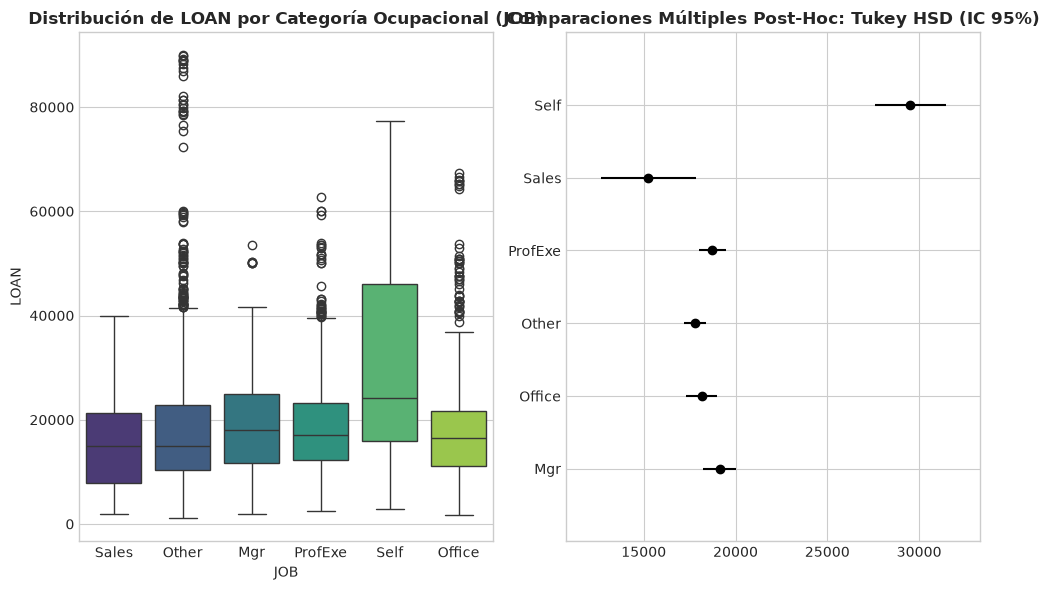

Comparaciones Post-Hoc Welch con corrección de Bonferroni:


,Grupo_1,Grupo_2,Diff_Medias,Welch_t,p_raw,p_bonferroni,Rechaza_H0
0,Mgr,Office,-979.1940,1.7835,0.0747,1.0000,False
1,Mgr,Other,-1347.2723,2.9293,0.0035,0.0520,False
2,Mgr,ProfExe,-399.2835,0.8210,0.4118,1.0000,False
3,Mgr,Sales,-3887.8067,4.1718,0.0001,0.0008,True
4,Mgr,Self,10384.4686,-6.6318,0.0000,0.0000,True
5,Office,Other,-368.0783,0.7929,0.4280,1.0000,False
6,Office,ProfExe,579.9105,-1.1826,0.2372,1.0000,False
7,Office,Sales,-2908.6127,3.1140,0.0023,0.0339,True
8,Office,Self,11363.6627,-7.2513,0.0000,0.0000,True
9,Other,ProfExe,947.9888,-2.4430,0.0146,0.2196,False


In [7]:
# Q-Q Plots por grupo ocupacional y Boxplot comparativo + Post-hoc Tukey HSD
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.boxplot(data=train_df, x=ANOVA_FACTOR, y=ANOVA_VARIABLE, hue=ANOVA_FACTOR, palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Distribución de LOAN por Categoría Ocupacional (JOB)', fontweight='bold')

anova_res['tukey_posthoc'].plot_simultaneous(ax=axes[1])
axes[1].set_title('Comparaciones Múltiples Post-Hoc: Tukey HSD (IC 95%)', fontweight='bold')
plt.tight_layout()
plt.show()

print("Comparaciones Post-Hoc Welch con corrección de Bonferroni:")
display(anova_res['bonferroni_welch_posthoc'])


---

## 📐 FASE 2: Diagnóstico Econométrico de Gauss-Markov, Puntos Influyentes y Reducción PCA
*(Articulación directa con Unidad 3)*

### 2.1 Ajuste del Modelo Lineal Clásico de Referencia (MCO) sobre `train.csv`
Estimamos el modelo de regresión lineal múltiple sobre las 9 covariables numéricas basales para explicar el monto de préstamo solicitado (`LOAN`):
$$Y = \beta_0 + \beta_1 X_1 + \dots + \beta_9 X_9 + \varepsilon$$


In [8]:
tr_df, te_df, pred_cols = load_phase2_splits()
X_train_ols, y_train_ols = tr_df[pred_cols], tr_df[TARGET_CONTINUOUS]
X_test_ols, y_test_ols = te_df[pred_cols], te_df[TARGET_CONTINUOUS]

ols_model = fit_ols_reference(X_train_ols, y_train_ols)
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:                   LOAN   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.120
Method:                 Least Squares   F-statistic:                     73.33
Date:                Sun, 15 Nov 2026   Prob (F-statistic):          2.24e-127
Time:                        16:26:43   Log-Likelihood:                -50924.
No. Observations:                4768   AIC:                         1.019e+05
Df Residuals:                    4758   BIC:                         1.019e+05
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       9059.1303    836.428     10.831      0.0

### 2.2 Auditoría Exhaustiva de Supuestos de Gauss-Markov
Contrastamos homocedasticidad (**Breusch-Pagan** y **White**), normalidad de residuos (**Jarque-Bera** y Q-Q Plot) e independencia (**Durbin-Watson**).


Breusch-Pagan : LM = 118.2555, p = 3.0395e-21 | Homocedástico: False
Test de White : LM = 451.7230, p = 3.6034e-64 | Homocedástico: False
Jarque-Bera   : JB = 16199.34, p = 0.0000e+00, Skew = 2.11, Kurt = 10.98
Durbin-Watson : DW = 1.9738 | Independencia serial OK: True


<>:11: SyntaxWarning: invalid escape sequence '\h'
<>:11: SyntaxWarning: invalid escape sequence '\h'
C:\Users\German\AppData\Local\Temp\ipykernel_6316\1246963511.py:11: SyntaxWarning: invalid escape sequence '\h'
  axes[0].set_xlabel('Valores Ajustados ($\hat{y}$)')


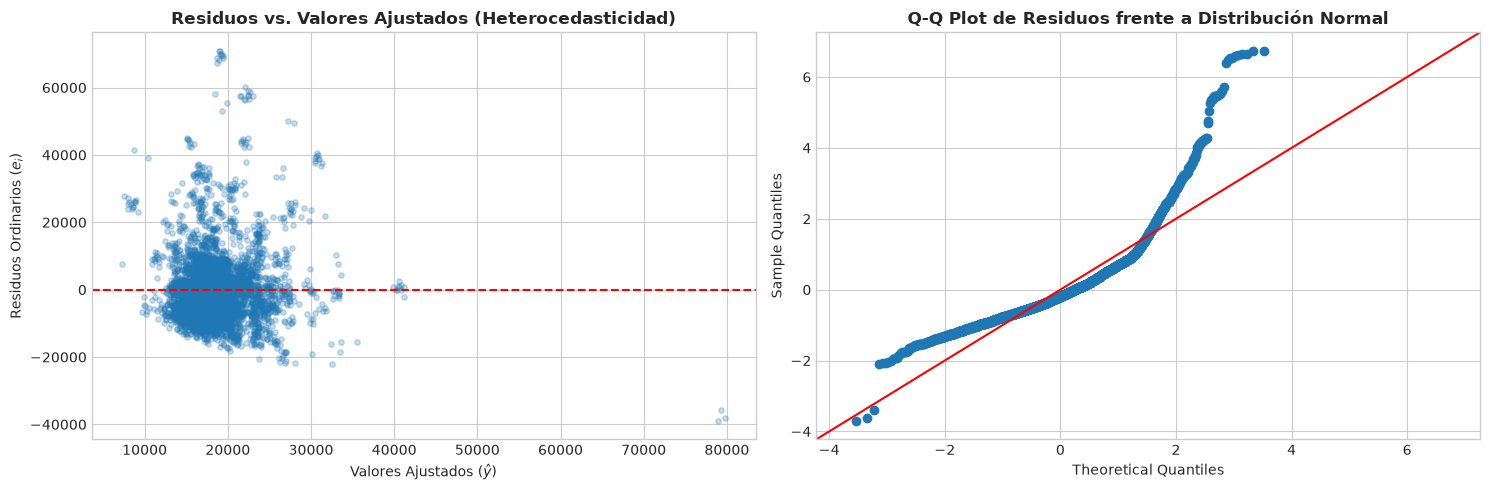

In [9]:
gm_audit = audit_gauss_markov(ols_model)
print(f"Breusch-Pagan : LM = {gm_audit['breusch_pagan']['lm_stat']:.4f}, p = {gm_audit['breusch_pagan']['p_value']:.4e} | Homocedástico: {gm_audit['breusch_pagan']['is_homoscedastic']}")
print(f"Test de White : LM = {gm_audit['white_test']['lm_stat']:.4f}, p = {gm_audit['white_test']['p_value']:.4e} | Homocedástico: {gm_audit['white_test']['is_homoscedastic']}")
print(f"Jarque-Bera   : JB = {gm_audit['jarque_bera']['jb_stat']:.2f}, p = {gm_audit['jarque_bera']['p_value']:.4e}, Skew = {gm_audit['jarque_bera']['skewness']:.2f}, Kurt = {gm_audit['jarque_bera']['kurtosis']:.2f}")
print(f"Durbin-Watson : DW = {gm_audit['durbin_watson']['dw_stat']:.4f} | Independencia serial OK: {gm_audit['durbin_watson']['is_independent']}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(ols_model.fittedvalues, ols_model.resid, alpha=0.25, s=15, color='#1f77b4')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuos vs. Valores Ajustados (Heterocedasticidad)', fontweight='bold')
axes[0].set_xlabel('Valores Ajustados ($\hat{y}$)')
axes[0].set_ylabel('Residuos Ordinarios ($e_i$)')

sm.qqplot(ols_model.resid, line='45', fit=True, ax=axes[1])
axes[1].set_title('Q-Q Plot de Residuos frente a Distribución Normal', fontweight='bold')
plt.tight_layout()
plt.show()


### 2.3 Detección de Observaciones Extremas, Distancia de Cook ($D_i$) y Regresión Robusta
Descomponemos outliers de respuesta ($|r_i| > 3$), apalancamiento ($h_{ii} > \frac{2(p+1)}{n}$) e influencia global ($D_i = \frac{e_i^2}{(p+1)\text{MSE}} \left[\frac{h_{ii}}{(1-h_{ii})^2}\right]$), y evaluamos la remediación mediante **Huber** y **RANSAC** sobre el conjunto de prueba (`test.csv`).


Outliers de respuesta (|r_i| > 3)     : 98
Alto apalancamiento (h_ii > 0.00419) : 386
Puntos influyentes (Cook's D > 4/n)  : 268 (Max D_i = 0.1687)


,Modelo,Test_RMSE,Test_MAE
0,MCO (OLS),10204.5100,6986.2695
1,Huber Robusto,10382.6744,6785.4514
2,RANSAC Robusto,11850.9792,7584.3176


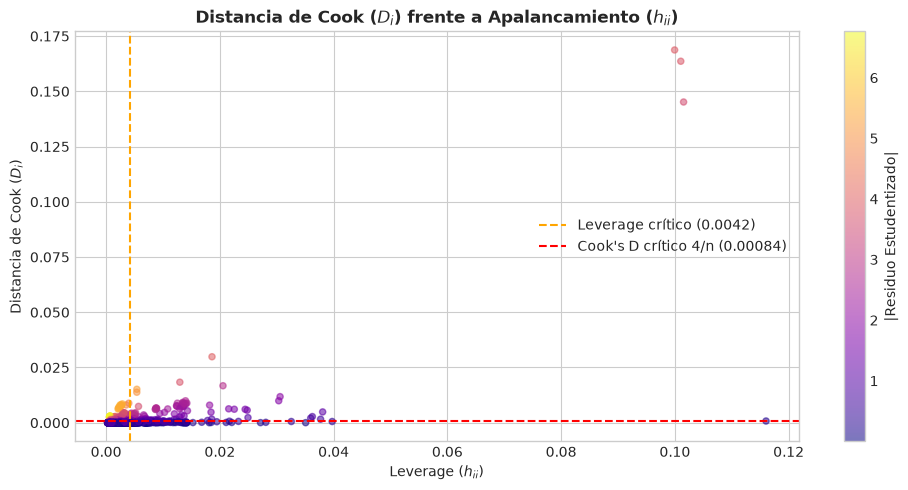

In [10]:
infl_res = detect_influential_points(ols_model, X_train_ols)
print(f"Outliers de respuesta (|r_i| > 3)     : {infl_res['count_outliers_resid']}")
print(f"Alto apalancamiento (h_ii > {infl_res['thresh_leverage']:.5f}) : {infl_res['count_high_leverage']}")
print(f"Puntos influyentes (Cook's D > 4/n)  : {infl_res['count_high_cooks_4n']} (Max D_i = {infl_res['max_cooks_d']:.4f})")

comp_robust = compare_robust_regressors(X_train_ols, y_train_ols, X_test_ols, y_test_ols, ols_model)
display(comp_robust)

fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(infl_res['leverage'], infl_res['cooks_distance'], c=np.abs(infl_res['stud_resids']), cmap='plasma', alpha=0.55, s=20)
ax.axvline(infl_res['thresh_leverage'], color='orange', linestyle='--', label=f"Leverage crítico ({infl_res['thresh_leverage']:.4f})")
ax.axhline(infl_res['thresh_cook_4n'], color='red', linestyle='--', label=f"Cook's D crítico 4/n ({infl_res['thresh_cook_4n']:.5f})")
plt.colorbar(sc, ax=ax, label='|Residuo Estudentizado|')
ax.set_title("Distancia de Cook ($D_i$) frente a Apalancamiento ($h_{ii}$)", fontweight='bold')
ax.set_xlabel('Leverage ($h_{ii}$)')
ax.set_ylabel("Distancia de Cook ($D_i$)")
ax.legend()
plt.tight_layout()
plt.show()


### 2.4 Diagnóstico de Multicolinealidad (VIF)
Calculamos $\text{VIF}_j = \frac{1}{1 - R_j^2}$ sobre las covariables de entrenamiento para auditar redundancia estructural.


In [11]:
df_vif = calculate_vif(X_train_ols)
display(df_vif)


,Variable,VIF,Alerta_VIF_5,Alerta_VIF_10
0,MORTDUE,2.7700,False,False
1,VALUE,2.6698,False,False
2,CLNO,1.2249,False,False
3,CLAGE,1.1341,False,False
4,YOJ,1.0651,False,False
5,DEROG,1.0610,False,False
6,DELINQ,1.0596,False,False
7,NINQ,1.0560,False,False
8,DEBTINC,1.0522,False,False


### 2.5 Reducción de Dimensionalidad con PCA (Estrictamente Ajustado en Train)
Siguiendo la regla anti-leakage, `StandardScaler` y `PCA` se ajustan **únicamente sobre `train.csv`** y transforman `test.csv` de manera ciega. Retenemos componentes bajo el **criterio de Kaiser ($\lambda_k > 1$)**.


In [12]:
pca_res = run_pca_no_leakage(tr_df, te_df, pred_cols)

pca_table = pd.DataFrame({
    'Autovalor (Lambda)': pca_res['eigenvalues'],
    'Varianza (%)': pca_res['var_exp_ratio'] * 100,
    'Varianza Acumulada (%)': pca_res['cum_var_exp'] * 100,
    'Retenido (Kaiser > 1)': pca_res['eigenvalues'] > 1.0
}, index=[f"PC{i+1}" for i in range(len(pca_res['eigenvalues']))])
display(pca_table)
print(f"Componentes retenidos según Kaiser (Lambda > 1): {pca_res['kaiser_retained_count']}")


,Autovalor (Lambda),Varianza (%),Varianza Acumulada (%),Retenido (Kaiser > 1)
PC1,2.0852,23.1639,23.1639,True
PC2,1.3795,15.3249,38.4888,True
PC3,1.2443,13.8229,52.3117,True
PC4,0.9649,10.7191,63.0308,False
PC5,0.8756,9.7263,72.7571,False
PC6,0.8234,9.1469,81.9040,False
PC7,0.7803,8.6685,90.5724,False
PC8,0.6425,7.1375,97.7100,False
PC9,0.2061,2.2900,100.0000,False


Componentes retenidos según Kaiser (Lambda > 1): 3


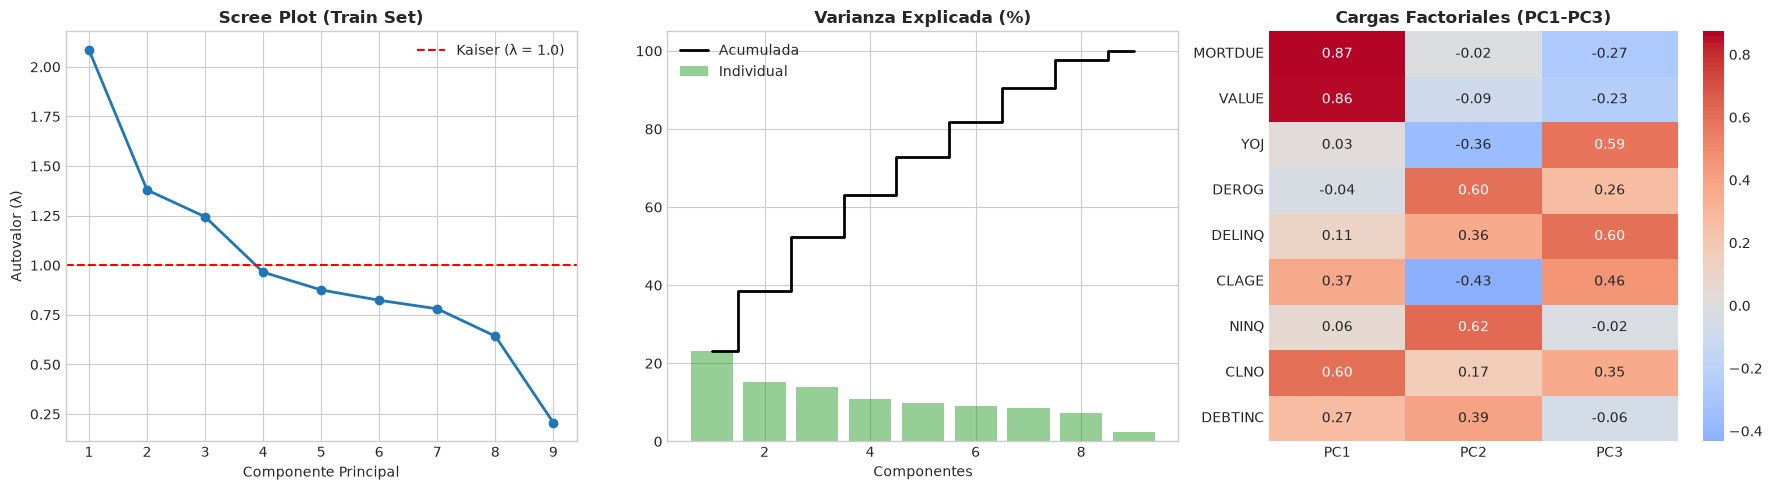

In [13]:
# Scree Plot, Varianza Acumulada y Matriz de Cargas (Loadings)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(range(1, len(pca_res['eigenvalues']) + 1), pca_res['eigenvalues'], 'o-', color='#1f77b4', lw=2)
axes[0].axhline(1.0, color='red', linestyle='--', label='Kaiser (λ = 1.0)')
axes[0].set_title('Scree Plot (Train Set)', fontweight='bold')
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('Autovalor (λ)')
axes[0].legend()

axes[1].bar(range(1, len(pca_res['var_exp_ratio']) + 1), pca_res['var_exp_ratio'] * 100, alpha=0.5, color='#2ca02c', label='Individual')
axes[1].step(range(1, len(pca_res['cum_var_exp']) + 1), pca_res['cum_var_exp'] * 100, where='mid', color='black', lw=2, label='Acumulada')
axes[1].set_title('Varianza Explicada (%)', fontweight='bold')
axes[1].set_xlabel('Componentes')
axes[1].legend()

sns.heatmap(pca_res['loadings'].iloc[:, :3], annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[2])
axes[2].set_title('Cargas Factoriales (PC1-PC3)', fontweight='bold')

plt.tight_layout()
plt.show()


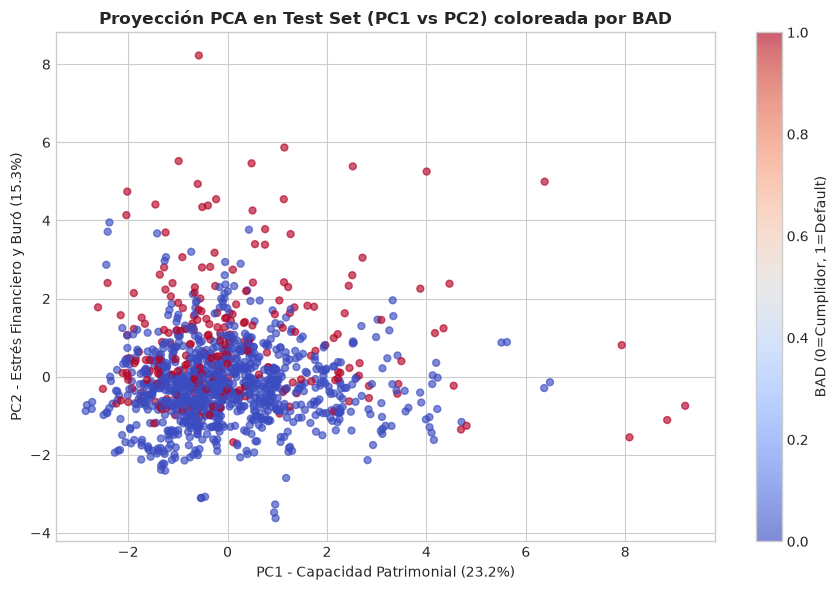

In [14]:
# Proyección 2D en Test (ciega) diferenciada por Default (BAD)
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(
    pca_res['X_test_pca'][:, 0], pca_res['X_test_pca'][:, 1],
    c=te_df[TARGET_BINARY], cmap='coolwarm', alpha=0.65, s=25
)
ax.set_title('Proyección PCA en Test Set (PC1 vs PC2) coloreada por BAD', fontweight='bold')
ax.set_xlabel(f"PC1 - Capacidad Patrimonial ({pca_res['var_exp_ratio'][0]*100:.1f}%)")
ax.set_ylabel(f"PC2 - Estrés Financiero y Buró ({pca_res['var_exp_ratio'][1]*100:.1f}%)")
plt.colorbar(scatter, ax=ax, label='BAD (0=Cumplidor, 1=Default)')
plt.tight_layout()
plt.show()


---

# 🌲 FASE 3: Torneo de Modelos Predictivos y Calibración *(Unidades 4 y 5)*

**Responsable de Workflow:** Martín Peña (Machine Learning Engineer)  
**Pregunta de la fase:** Dado el perfil de un solicitante, ¿qué probabilidad calibrada tiene de entrar en default (`BAD = 1`)?  
Es una pregunta estrictamente **observacional / predictiva** (Nivel 1 de Pearl: $P(Y \mid X)$). Evaluamos cuatro familias sobre la partición congelada (`train.csv` = 4.768, `test.csv` = 1.192) sin fuga de datos.

**Pila y Protocolo:**
1. Regresión Logística Clásica (`statsmodels.Logit` con Odds Ratios) + Regularización Elastic Net (`GridSearchCV`, `cv=5`).
2. Naive Bayes (`GaussianNB`) + Auditoría de correlación intra-clase + **Calibración Isotónica**.
3. Árbol de Decisión CART completo vs. Poda Cost-Complexity (`ccp_alpha` óptimo en CV).
4. Random Forest (`RandomizedSearchCV` + convergencia *Out-Of-Bag*).
5. Comparación unificada en Test (`Precision`, `Recall`, `F1`, `AUC-ROC`, `PR-AUC`, `Brier Score`), Diagramas de Calibración, MDI vs. Permutation Importance y ablación de `DEBTINC_is_missing`.


In [15]:
from sklearn.tree import plot_tree
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from sklearn.calibration import calibration_curve

from src.phase3_ml import (
    load_phase3_data,
    fit_logistic_suite,
    fit_naive_bayes_and_calibration,
    fit_decision_tree_pruning,
    fit_random_forest_tournament,
    evaluate_models_test,
    compute_feature_importance_comparison,
    run_debtinc_missing_ablation,
)

train_ml, test_ml, X_train_ml, X_test_ml, y_train_ml, y_test_ml = load_phase3_data()
print(f"Matriz X_train: {X_train_ml.shape} | Tasa default Train: {y_train_ml.mean():.2%}")
print(f"Matriz X_test : {X_test_ml.shape} | Tasa default Test : {y_test_ml.mean():.2%}")
print(f"17 predictoras (referencia JOB = Mgr): {list(X_train_ml.columns)}")


Matriz X_train: (4768, 17) | Tasa default Train: 19.95%
Matriz X_test : (1192, 17) | Tasa default Test : 19.97%
17 predictoras (referencia JOB = Mgr): ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC', 'TREATMENT', 'DEBTINC_is_missing', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']


### 3.1 Regresión Logística Clásica (Odds Ratios) y Regularización Elastic Net
Ajustamos primero `Logit` sin penalización para interpretar Odds Ratios *ceteris paribus*, y luego evaluamos `GridSearchCV` sobre Elastic Net (`Ridge L2`, `Elastic Net`, `Lasso L1`).


In [16]:
logit_res = fit_logistic_suite(X_train_ml, y_train_ml)
print(f"Pseudo R² de McFadden: {logit_res['pseudo_r2']:.4f} | Test LR global: p = {logit_res['llr_pvalue']:.2e}")
display(logit_res['or_table'].round(4))

print(f"\nMejor configuración Elastic Net: {logit_res['best_params']} -> AUC CV = {logit_res['best_cv_auc']:.4f}")
cv_grid = logit_res['cv_results'].pivot(
    index="param_logisticregression__C",
    columns="param_logisticregression__l1_ratio",
    values="mean_test_score",
).rename_axis(index="C", columns="l1_ratio")
display(cv_grid.round(4))

print("Comparación de coeficientes estandarizados (C=0.01): Ridge vs. Lasso")
display(logit_res['pen_comparison'].sort_values("Ridge_L2", key=abs, ascending=False).round(3))


Pseudo R² de McFadden: 0.4022 | Test LR global: p = 0.00e+00


,Incremento,OR,IC_95_inf,IC_95_sup,p_valor
LOAN,+ USD 10.000,0.9295,0.8436,1.0242,0.1396
MORTDUE,+ USD 10.000,0.9658,0.9330,0.9999,0.0491
VALUE,+ USD 10.000,1.0237,0.9988,1.0491,0.0620
YOJ,+ 1 unidad,0.9875,0.9733,1.0019,0.0894
DEROG,+ 1 unidad,1.7131,1.5162,1.9356,0.0000
DELINQ,+ 1 unidad,2.1193,1.9188,2.3408,0.0000
CLAGE,+ 1 año,0.9322,0.9167,0.9481,0.0000
NINQ,+ 1 unidad,1.1194,1.0609,1.1810,0.0000
CLNO,+ 1 unidad,0.9877,0.9773,0.9982,0.0215
DEBTINC,+ 1 unidad,1.0876,1.0681,1.1075,0.0000



Mejor configuración Elastic Net: {'logisticregression__C': 0.01, 'logisticregression__l1_ratio': 0.0} -> AUC CV = 0.8908


l1_ratio,0.0000,0.5000,1.0000
C,,,
0.0100,0.8908,0.8874,0.8859
0.1000,0.8904,0.8905,0.8904
1.0000,0.8903,0.8903,0.8903
10.0000,0.8902,0.8902,0.8903


Comparación de coeficientes estandarizados (C=0.01): Ridge vs. Lasso


,Ridge_L2,Lasso_L1
DEBTINC_is_missing,0.9270,0.9360
DELINQ,0.6210,0.5010
DEBTINC,0.4130,0.2310
CLAGE,-0.3640,-0.2800
DEROG,0.3520,0.2640
JOB_Office,-0.1730,-0.0130
NINQ,0.1660,0.0390
JOB_Sales,0.1100,0.0000
TREATMENT,-0.1030,0.0000
MORTDUE,-0.0910,0.0000


**Lectura de resultados (3.1).** El modelo es globalmente significativo y su pseudo $R^2$ de McFadden de 0,40 indica un muy buen ajuste (en esta medida, valores entre 0,2 y 0,4 ya se consideran excelentes). Los efectos, *ceteris paribus*:

- **Historial negativo.** Cada línea de crédito en mora (`DELINQ`) multiplica los odds de default por **2,12**, y cada reporte derogatorio (`DEROG`) por **1,71**.
- **Endeudamiento.** Cada punto del ratio deuda/ingreso (`DEBTINC`) aumenta los odds un 8,8 %, y cada consulta crediticia reciente (`NINQ`) un 11,9 %.
- **Antigüedad crediticia.** Cada año más de la línea más antigua (`CLAGE`) los reduce un 6,8 %.
- **Dato faltante.** No haber informado el ratio deuda/ingreso multiplica los odds por **14,7**: es el efecto más grande del modelo y coincide con el mecanismo MAR/MNAR detectado en la Fase 1.
- **Ocupación** (referencia: gerentes): vendedores 2,70, cuentapropistas 1,89 y administrativos 0,53.
- **Tratamiento.** Los créditos para consolidar deuda muestran odds un 24 % menores (OR = 0,76; IC 95 %: 0,61 a 0,94). Es una **asociación condicional, no un efecto causal**: esa pregunta la responde la Fase 4.
- El monto del préstamo, el valor de la propiedad y los años de empleo no son significativos al 5 %.

**Regularización.** Las doce combinaciones de la grilla dan un AUC de validación cruzada entre 0,886 y 0,891: la penalización casi no cambia el desempeño. Con 4.768 observaciones y 17 predictoras, el modelo sin penalizar ya estaba lejos del sobreajuste. La diferencia entre Ridge y Lasso aparece en los coeficientes: con la misma penalización fuerte ($C = 0{,}01$), Ridge conserva las 17 variables con coeficientes encogidos, mientras que Lasso **anula 10** y se queda con 7 (faltante de `DEBTINC`, moras, ratio deuda/ingreso, antigüedad, derogatorios, consultas y ocupación administrativa). Entre las descartadas está `TREATMENT`: el propósito del crédito no sobrevive como predictor, lo que no implica que no tenga efecto causal.

### 3.2 Naive Bayes (`GaussianNB`) y Calibración Isotónica
`GaussianNB` asume independencia condicional entre features dado `BAD`. Auditamos la correlación intra-clase real y corregimos la subestimación probabilística mediante **Calibración Isotónica (`cv=5`)**.


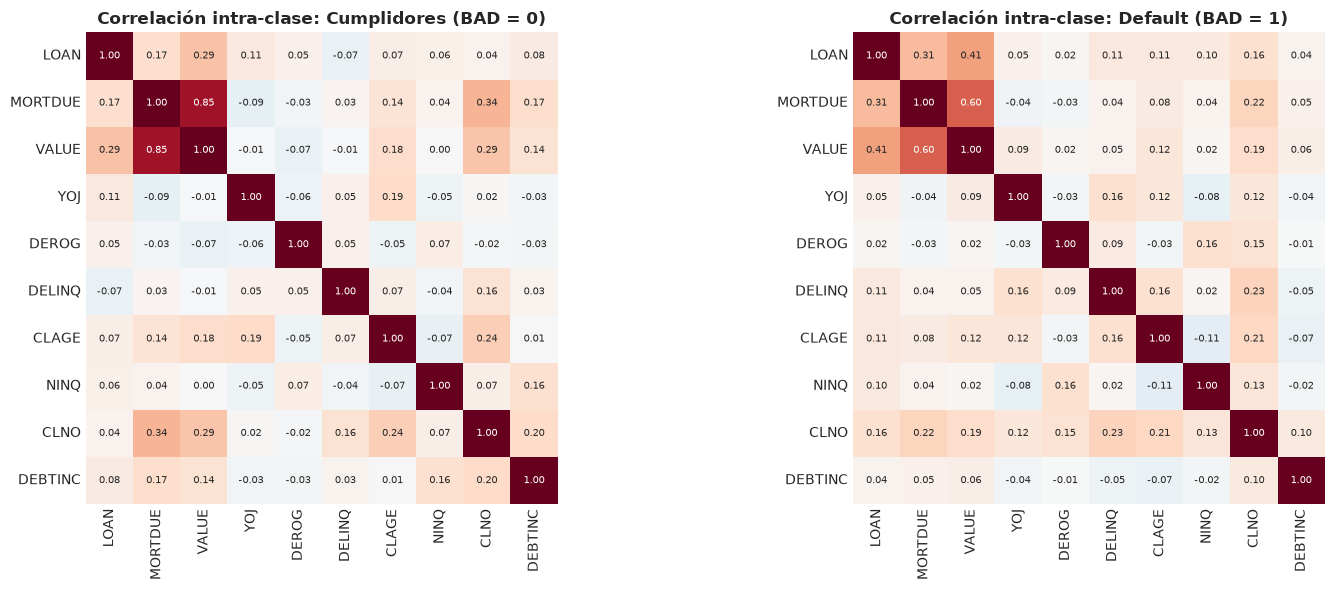

,Prob_media,Error_calibracion,Brier,AUC_ROC,Recall_05
Modelo,,,,,
Naive Bayes original,0.1245,0.0752,0.1399,0.7645,0.1849
Naive Bayes calibrado,0.2012,0.0235,0.1297,0.7649,0.2731


In [17]:
nb_res = fit_naive_bayes_and_calibration(X_train_ml, y_train_ml, X_test_ml, y_test_ml)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, corr_df, title in zip(
    axes,
    [nb_res['corr_paid'], nb_res['corr_default']],
    ["Correlación intra-clase: Cumplidores (BAD = 0)", "Correlación intra-clase: Default (BAD = 1)"]
):
    sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                cbar=False, square=True, annot_kws={"size": 7}, ax=ax)
    ax.set_title(title, fontweight="bold")
plt.tight_layout()
plt.show()

display(nb_res['calibration_comparison'].round(4))


**Lectura de resultados (3.2).** El supuesto de independencia condicional **no se cumple**: dentro de los cumplidores, la hipoteca adeudada (`MORTDUE`) y el valor de la propiedad (`VALUE`) correlacionan 0,85 (0,60 entre los morosos), algo esperable porque la deuda hipotecaria depende del valor del inmueble. Naive Bayes las trata como dos evidencias independientes y cuenta dos veces la misma información. Además, varias predictoras son conteos o binarias, lejos de la distribución normal que asume `GaussianNB`.

La consecuencia se ve en la calibración: el modelo original **subestima el riesgo**, con una probabilidad media de 12,5 % frente a una tasa real de 20 %. Por eso, con umbral 0,5, detecta solo el 18 % de los defaults. La calibración isotónica (ajustada con validación cruzada sobre train, sin tocar test) corrige el nivel: la probabilidad media pasa a 20,1 %, el error de calibración baja de 0,075 a 0,024 y el Brier de 0,140 a 0,130.

Lo que **no cambia es el AUC** (0,765): la calibración isotónica es una transformación creciente, así que conserva el orden de los clientes. Corrige *cuánto* riesgo se asigna, no *a quién* se considera más riesgoso. El problema de fondo, la información contada dos veces, no se arregla calibrando.

### 3.3 Árbol de Decisión CART: Sobreajuste sin Poda vs. Poda `ccp_alpha`
Un árbol sin restricciones memoriza `train.csv`. Aplicamos **Cost-Complexity Pruning** eligiendo el $\alpha$ óptimo por validación cruzada estratificada.


Árbol sin poda : 443 hojas (prof=29) | AUC Train=1.0000 | AUC Test=0.7874
Árbol podado   : 30 hojas (prof=12) | AUC Train=0.9142 | AUC Test=0.8834


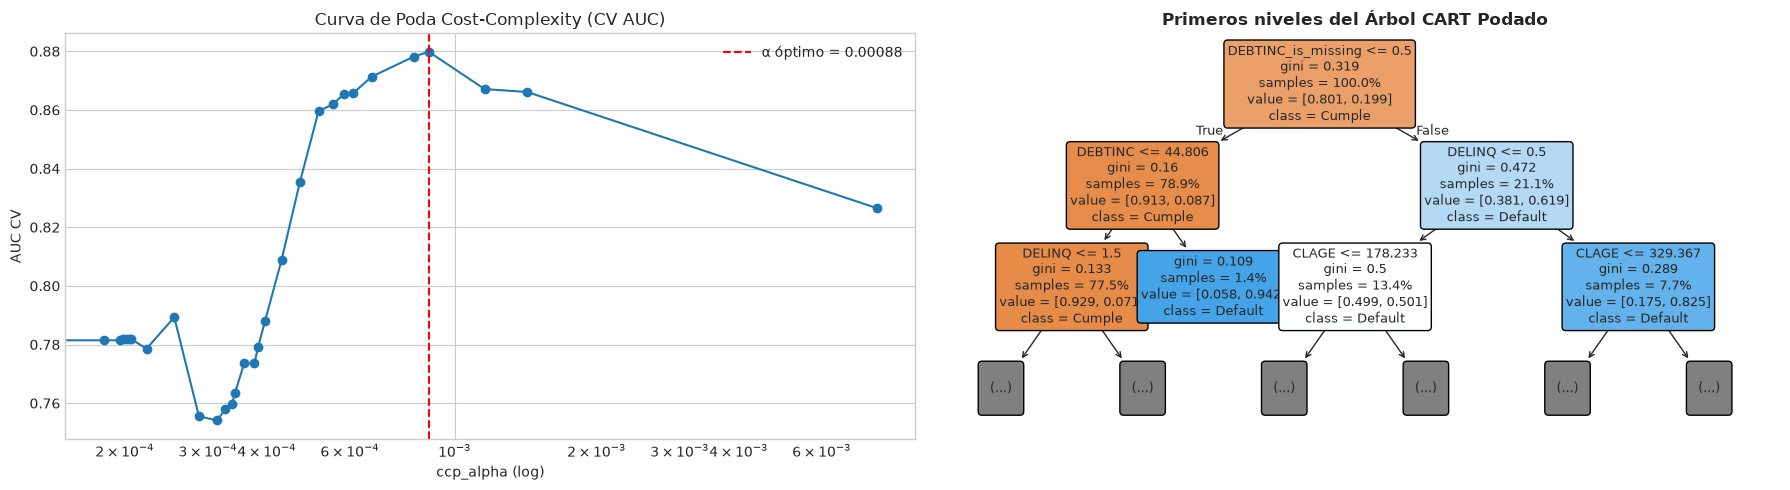

In [18]:
tree_res = fit_decision_tree_pruning(X_train_ml, y_train_ml, X_test_ml, y_test_ml)
print(f"Árbol sin poda : {tree_res['full_stats']['leaves']} hojas (prof={tree_res['full_stats']['depth']}) | AUC Train={tree_res['full_stats']['auc_train']:.4f} | AUC Test={tree_res['full_stats']['auc_test']:.4f}")
print(f"Árbol podado   : {tree_res['pruned_stats']['leaves']} hojas (prof={tree_res['pruned_stats']['depth']}) | AUC Train={tree_res['pruned_stats']['auc_train']:.4f} | AUC Test={tree_res['pruned_stats']['auc_test']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
curve = tree_res['pruning_curve']
axes[0].plot(curve['alpha'], curve['auc_cv'], 'o-')
axes[0].axvline(tree_res['best_alpha'], color='red', ls='--', label=f"α óptimo = {tree_res['best_alpha']:.5f}")
axes[0].set_xscale('log')
axes[0].set(title='Curva de Poda Cost-Complexity (CV AUC)', xlabel='ccp_alpha (log)', ylabel='AUC CV')
axes[0].legend()

plot_tree(tree_res['tree_pruned'], max_depth=2, feature_names=list(X_train_ml.columns),
          class_names=["Cumple", "Default"], filled=True, rounded=True, proportion=True, fontsize=9, ax=axes[1])
axes[1].set_title('Primeros niveles del Árbol CART Podado', fontweight='bold')
plt.tight_layout()
plt.show()


**Lectura de resultados (3.3).** Sin restricciones, el árbol crece hasta 443 hojas y 29 niveles: clasifica perfecto el entrenamiento (AUC = 1,000) pero cae a 0,787 en test. No aprendió el patrón del riesgo, **memorizó** los datos con su ruido. La poda por complejidad de costo, $R_\alpha(T) = R(T) + \alpha|T|$, penaliza la cantidad de hojas $|T|$; con el $\alpha$ elegido por validación cruzada el árbol queda en **30 hojas**, su AUC en test sube a **0,883** y la brecha entre train y test se reduce de 0,21 a 0,03. La curva muestra el patrón típico: con $\alpha$ muy chico el árbol sobreajusta y con $\alpha$ muy grande queda demasiado simple.

**Regla del nodo raíz:** `DEBTINC_is_missing ≤ 0.5`. Lo primero que pregunta el árbol es si el cliente informó su ratio deuda/ingreso, porque es el corte que más reduce la impureza de Gini.

- **Con el dato** (79 % de los clientes, 8,7 % de default): la siguiente pregunta es el nivel del ratio. Quienes superan 44,8 son muy pocos, pero tienen un 94 % de default.
- **Sin el dato** (21 % de los clientes, 61,9 % de default): la siguiente pregunta es si tienen alguna línea en mora. Con al menos una, el default sube a 82,5 %; sin ninguna, queda en 50,1 %.

Es una regla que un analista de crédito reconocería: primero, ¿documentó su capacidad de pago?; después, ¿cuán endeudado está o cuántas veces se atrasó?

### 3.4 Random Forest (`RandomizedSearchCV`) y Convergencia *Out-Of-Bag* (OOB)
Ensamblamos árboles decorrelacionados por *bagging* y submuestreo de variables (`max_features`), validando convergencia mediante la cota OOB sin consumo de partición Test.


Mejores hiperparámetros RF: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}
AUC ROC en CV (Train)     : 0.9490


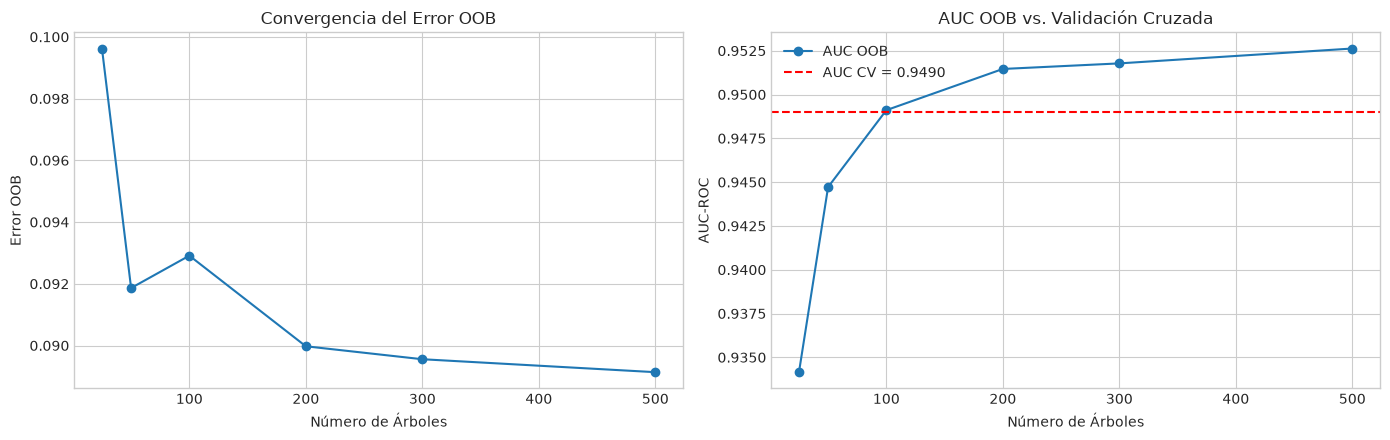

,n_arboles,error_oob,auc_oob
0,25,0.0996,0.9342
1,50,0.0919,0.9447
2,100,0.0929,0.9491
3,200,0.0900,0.9515
4,300,0.0896,0.9518
5,500,0.0891,0.9526


In [19]:
rf_res = fit_random_forest_tournament(X_train_ml, y_train_ml)
print(f"Mejores hiperparámetros RF: {rf_res['best_params']}")
print(f"AUC ROC en CV (Train)     : {rf_res['best_cv_auc']:.4f}")

oob = rf_res['oob_curve']
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(oob['n_arboles'], oob['error_oob'], 'o-')
axes[0].set(title='Convergencia del Error OOB', xlabel='Número de Árboles', ylabel='Error OOB')
axes[1].plot(oob['n_arboles'], oob['auc_oob'], 'o-', label='AUC OOB')
axes[1].axhline(rf_res['best_cv_auc'], color='red', ls='--', label=f"AUC CV = {rf_res['best_cv_auc']:.4f}")
axes[1].set(title='AUC OOB vs. Validación Cruzada', xlabel='Número de Árboles', ylabel='AUC-ROC')
axes[1].legend()
plt.tight_layout()
plt.show()
display(oob.round(4))


**Lectura de resultados (3.4).** La búsqueda aleatoria elige un bosque de 500 árboles sin límite de profundidad y con `max_features = "sqrt"` (cada corte elige entre unas 4 de las 17 variables), con AUC de 0,949 en validación cruzada.

**OOB frente a validación cruzada.** Cada árbol se entrena con una muestra bootstrap que deja afuera, en promedio, un 37 % de las filas; evaluar cada fila solo con los árboles que no la vieron da una estimación del error de generalización sin separar datos. El error OOB **converge**: baja de 0,100 con 25 árboles a 0,090 con 200 y se estabiliza en 0,089 con 500. El AUC OOB final (0,953) **coincide con el de la validación cruzada** (0,949): los dos estiman lo mismo, pero el OOB lo obtiene con un solo entrenamiento en lugar de cinco. Más allá de 300 árboles la mejora es marginal.

### 3.5 Evaluación Final en Test: Torneo Comparativo, Curvas ROC/PR y Calibración
Comparamos las 4 familias sobre los 1.192 casos ciegos de `test.csv`.


,Precision,Recall,F1_macro,F1_weighted,AUC_ROC,PR_AUC,Brier_Score,Mean_Pred_Prob
Modelo,,,,,,,,
Logística (Elastic Net),0.7840,0.5336,0.7807,0.8682,0.8775,0.7469,0.0910,0.1994
Naive Bayes,0.7857,0.1849,0.6004,0.7812,0.7645,0.5095,0.1399,0.1245
Naive Bayes Calibrado,0.6915,0.2731,0.6466,0.7997,0.7649,0.5180,0.1297,0.2012
Árbol sin poda,0.7136,0.6387,0.7990,0.8741,0.7874,0.5279,0.1233,0.1787
Árbol podado,0.7172,0.5966,0.7867,0.8679,0.8834,0.6744,0.0931,0.1953
Random Forest,0.7929,0.6597,0.8288,0.8940,0.9516,0.8408,0.0697,0.1887


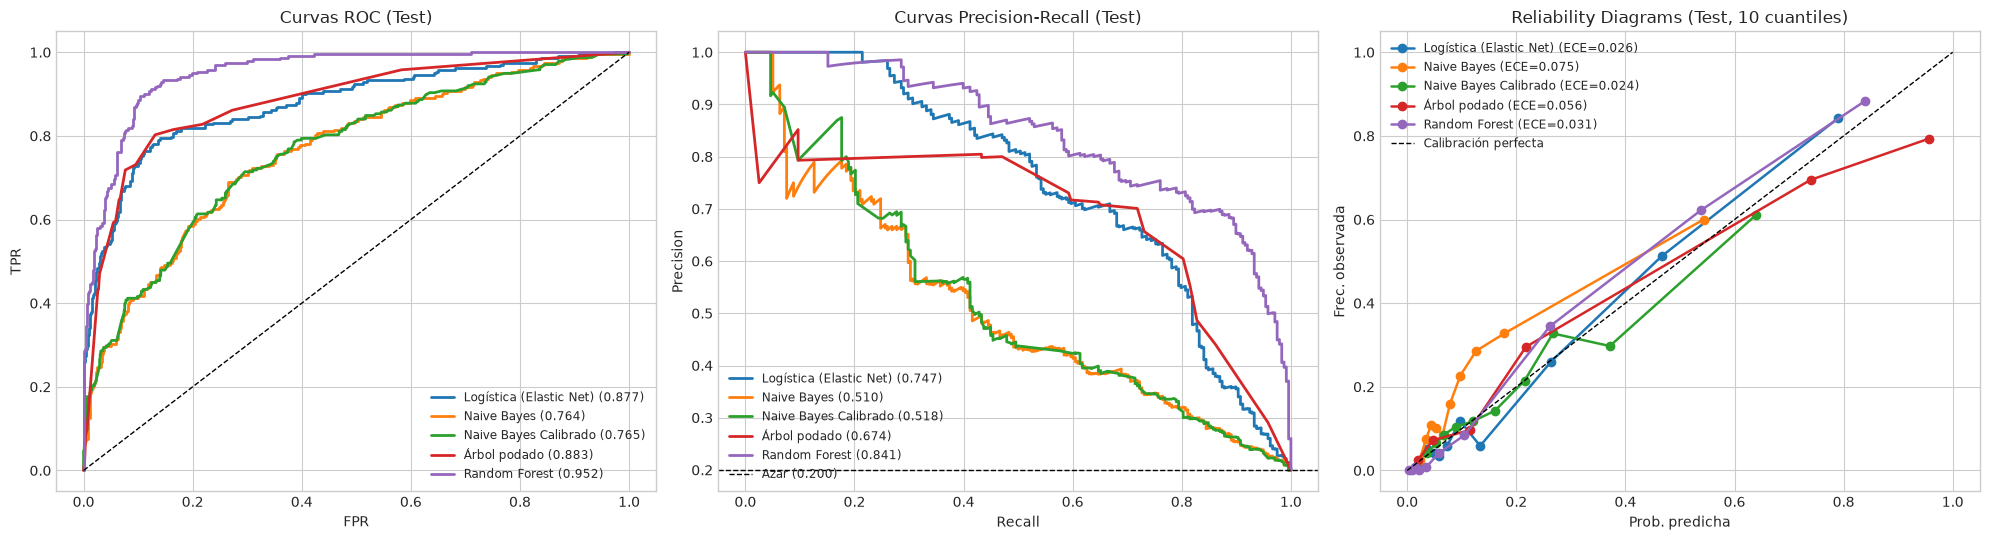

In [20]:
models_ml = {
    "Logística (Elastic Net)": logit_res['best_model'],
    "Naive Bayes": nb_res['nb_raw'],
    "Naive Bayes Calibrado": nb_res['nb_calibrated'],
    "Árbol sin poda": tree_res['tree_full'],
    "Árbol podado": tree_res['tree_pruned'],
    "Random Forest": rf_res['best_model'],
}
eval_res = evaluate_models_test(models_ml, X_test_ml, y_test_ml)
display(eval_res['metrics_table'].round(4))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for nombre in ["Logística (Elastic Net)", "Naive Bayes", "Naive Bayes Calibrado", "Árbol podado", "Random Forest"]:
    m_row = eval_res['metrics_table'].loc[nombre]
    roc_d = eval_res['roc_curves'][nombre]
    pr_d = eval_res['pr_curves'][nombre]
    cal_d = eval_res['calibration_curves'][nombre]
    axes[0].plot(roc_d['fpr'], roc_d['tpr'], lw=2, label=f"{nombre} ({m_row['AUC_ROC']:.3f})")
    axes[1].plot(pr_d['recall'], pr_d['precision'], lw=2, label=f"{nombre} ({m_row['PR_AUC']:.3f})")
    axes[2].plot(cal_d['pred'], cal_d['obs'], 'o-', lw=1.8, label=f"{nombre} (ECE={cal_d['ece_quantile']:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set(title='Curvas ROC (Test)', xlabel='FPR', ylabel='TPR')
axes[0].legend(loc='lower right', fontsize=8.5)

axes[1].axhline(y_test_ml.mean(), color='k', ls='--', lw=1, label=f"Azar ({y_test_ml.mean():.3f})")
axes[1].set(title='Curvas Precision-Recall (Test)', xlabel='Recall', ylabel='Precision')
axes[1].legend(loc='lower left', fontsize=8.5)

axes[2].plot([0, 1], [0, 1], 'k--', lw=1, label='Calibración perfecta')
axes[2].set(title='Reliability Diagrams (Test, 10 cuantiles)', xlabel='Prob. predicha', ylabel='Frec. observada')
axes[2].legend(loc='upper left', fontsize=8.5)
plt.tight_layout()
plt.show()


**Lectura de resultados (3.5).** El **Random Forest gana en todas las métricas**: AUC-ROC de 0,952, PR-AUC de 0,841 y el menor Brier (0,070). La logística y el árbol podado quedan cerca de 0,88 de AUC, y Naive Bayes último con 0,765.

- **El árbol sin poda** tiene más recall que la logística (0,64 frente a 0,53) pero un AUC mucho peor: sus hojas puras dan probabilidades de 0 o 1, que sirven en un umbral puntual pero ordenan mal a los clientes.
- **El F1 ponderado es más alto que el macro** en todos los modelos, porque da más peso a los cumplidores, la clase fácil. El macro trata a las dos clases por igual.
- **PR-AUC es la métrica más exigente** con 20 % de defaults: entre el bosque y Naive Bayes hay 0,19 de diferencia en AUC-ROC, pero 0,33 en PR-AUC.

**Calibración.** La logística es la mejor calibrada entre los modelos sin corregir (ECE = 0,026) y su probabilidad media (19,9 %) coincide con la tasa real: la máxima verosimilitud con intercepto fuerza esa igualdad. El Random Forest también está bien calibrado (ECE = 0,031) y en su tramo más alto predice algo menos que lo observado, porque promediar cientos de árboles empuja las probabilidades hacia el centro. El árbol podado es sobreconfiado arriba (ECE = 0,056): su último punto queda claramente por debajo de la diagonal, ya que sus hojas tienen pocos casos. Naive Bayes sin calibrar queda por encima de la diagonal (subestima el riesgo, ECE = 0,075) y la calibración isotónica lo lleva a 0,024.

**Modelo recomendado: Random Forest**, que es el que mejor discrimina y además entrega probabilidades confiables. La logística queda como complemento interpretable.

### 3.6 Diagnóstico de Importancia Predictiva (MDI vs. Permutation) y Ablación de `DEBTINC_is_missing`
Este análisis prepara el puente crítico hacia la **Fase 4 (Inferencia Causal)**: medimos qué variables dominan la predicción observacional frente a la variable de intervención `TREATMENT`, y auditamos cómo explotan los modelos el patrón de omisión MAR/MNAR detectado en Fase 1.


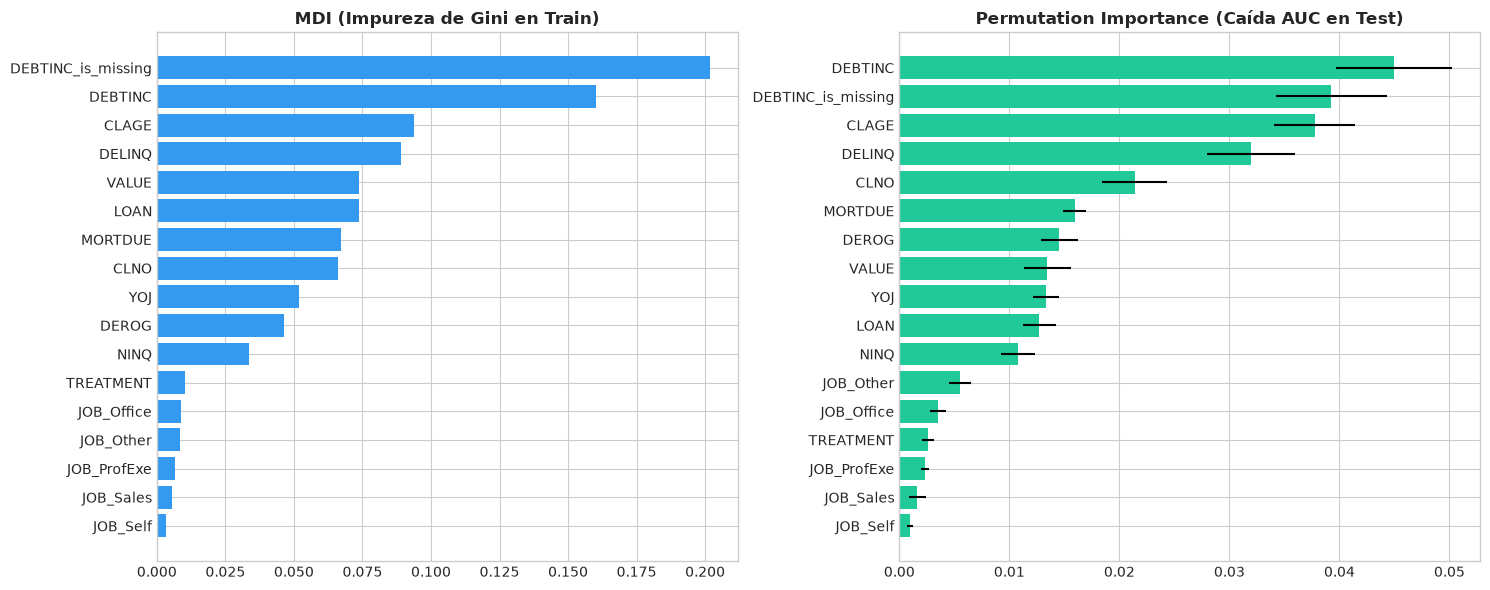

,MDI,Rank_MDI,Permutacion,Rank_Perm,Valores_distintos
DEBTINC,0.1602,2,0.0450,1,3763
DEBTINC_is_missing,0.2017,1,0.0393,2,2
CLAGE,0.0937,3,0.0378,3,4278
DELINQ,0.0890,4,0.0320,4,14
CLNO,0.0662,8,0.0214,5,62
MORTDUE,0.0670,7,0.0159,6,4064
DEROG,0.0466,10,0.0146,7,11
VALUE,0.0737,5,0.0134,8,4340
YOJ,0.0518,9,0.0133,9,90
LOAN,0.0736,6,0.0127,10,512



--- ABLACIÓN DE DEBTINC_is_missing Y DEBTINC ---


,AUC_Random_Forest,AUC_Logistica
Escenario,,
Todas las variables,0.9516,0.8795
Sin el indicador,0.9565,0.7638
Sin el indicador ni DEBTINC,0.9672,0.7432


In [21]:
imp_df = compute_feature_importance_comparison(rf_res['best_model'], X_train_ml, X_test_ml, y_test_ml)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ord_mdi = imp_df.sort_values('MDI').index
axes[0].barh(ord_mdi, imp_df.loc[ord_mdi, 'MDI'], color='#339af0')
axes[0].set_title('MDI (Impureza de Gini en Train)', fontweight='bold')

ord_perm = imp_df.sort_values('Permutacion').index
axes[1].barh(ord_perm, imp_df.loc[ord_perm, 'Permutacion'], xerr=imp_df.loc[ord_perm, 'Permutacion_SD'], color='#20c997')
axes[1].set_title('Permutation Importance (Caída AUC en Test)', fontweight='bold')
plt.tight_layout()
plt.show()

display(imp_df[['MDI', 'Rank_MDI', 'Permutacion', 'Rank_Perm', 'Valores_distintos']].round(4))

ablation_df = run_debtinc_missing_ablation(X_train_ml, y_train_ml, X_test_ml, y_test_ml, rf_res['best_params'])
print("\n--- ABLACIÓN DE DEBTINC_is_missing Y DEBTINC ---")
display(ablation_df.round(4))


**Lectura de resultados (3.6).** Los dos métodos coinciden en las cuatro variables principales (`DEBTINC`, su indicador de faltante, `CLAGE` y `DELINQ`), pero en el resto discrepan con una tendencia clara: las continuas con muchos valores distintos **pierden** puestos al pasar de MDI a permutación (`VALUE`, con 4.340 valores, baja del 5.º al 8.º; `LOAN`, con 512, del 6.º al 10.º) y las discretas con pocos valores los **ganan** (`CLNO`, con 62, sube del 8.º al 5.º; `DEROG`, con 11, del 10.º al 7.º). No es una regla exacta: `MORTDUE` sube un puesto.

**Por qué MDI está sesgada.** MDI suma cuánto reduce la impureza de Gini cada corte que usa una variable, **medido sobre los datos de entrenamiento**. Una variable con 4.340 valores distintos ofrece 4.339 puntos de corte posibles; una dummy, uno solo. Con tantas opciones, el árbol casi siempre encuentra algún corte de la continua que reduce un poco la impureza **por azar**, y esos cortes espurios se acumulan como importancia. Como estos árboles crecen sin límite de profundidad, los cortes se hacen sobre grupos cada vez más chicos, donde el ruido pesa más.

**Cómo lo neutraliza la permutación.** Mide cuánto **cae el AUC en test** al desordenar una variable. No mira cómo se construyó el árbol, sino cuánto depende la predicción de esa variable en datos nuevos; los cortes espurios no generalizan, así que en test no aportan nada. El sesgo de MDI favorece a las continuas, pero no impide que domine una binaria muy informativa: `DEBTINC_is_missing` es primera en MDI porque su único corte separa grupos con 62 % y 9 % de default.

**Ablación.** Al quitar el indicador de faltante, la logística cae de 0,880 a 0,764 de AUC, pero el Random Forest **no pierde nada**, ni siquiera quitando también `DEBTINC` (0,967). Para un modelo lineal, los clientes imputados con la mediana quedan en el centro de la distribución, como si fueran de riesgo promedio, y sin el indicador no puede separarlos. El bosque, en cambio, encuentra sustitutos combinando de forma no lineal el resto de las variables. Dos precauciones: que el indicador sea la variable más importante no significa que el bosque la necesite, y el modelo sin esas variables no se adopta como ganador porque esa comparación se hizo sobre test, que no debe usarse para elegir modelos.

**Puente con la Fase 4.** `TREATMENT` queda 14.º de 17 en permutación y Lasso lo anula. Nada de eso habla de causalidad: la importancia predictiva mide asociación, no cuánto cambiaría el default si se interviniera sobre la variable.

---

# 🌐 FASE 4: Inferencia Causal, Modelos Estructurales (DAGs) y Causal Machine Learning (Workflow C)

**Responsable de Workflow:** Santiago Salvatore (Backend & Causal Machine Learning Engineer)  
**Marco Teórico Central:** Structural Causal Models (Pearl, 2000, 2009), Potential Outcomes Framework (Rubin, 1974; Neyman, 1923), y Double Machine Learning (Chernozhukov et al., 2018).  
**Pila Tecnológica:** `dowhy`, `econml`, `networkx`, `statsmodels`, `scikit-learn`, `scipy`.

---

### 4.0 Pregunta Estratégica de Negocio e Intervención de la Política Financiera

En las Fases 1 y 2 analizamos las distribuciones muestrales y los límites de los modelos econométricos tradicionales bajo las condiciones de Gauss-Markov. Sin embargo, en la gestión del riesgo crediticio bancario surge un interrogante de política activa que trasciende la simple predicción observacional:

$$\text{¿Cuál es el verdadero efecto causal de intervenir la política de destino crediticio, orientando activamente a los solicitantes hacia la } \mathbf{Consolidación\ de\ Pasivos} \ (T = 1, \text{DebtCon}) \ \text{frente a } \mathbf{Mejoras\ del\ Hogar} \ (T = 0, \text{HomeImp}), \ \text{sobre la probabilidad de cesación de pagos} \ (Y = 1, \text{BAD})?$$

Más aún: **¿Este efecto es homogéneo en toda la cartera de prestatarios, o existen subgrupos con respuestas radicalmente divergentes (heterogeneidad de tratamiento $\text{CATE}(x) = \tau(x)$)?**

Para responder con rigor metodológico, implementamos el flujo causal formal:
1. **Fundamentación Epistemológica:** De la Escalera de la Causalidad de Judea Pearl a los Resultados Potenciales de Donald Rubin.
2. **Especificación Estructural del DAG Formal:** Grafo Acíclico Dirigido en formato DOT, justificación de arcos y análisis de variables latentes no observadas ($U$).
3. **Identificación no Paramétrica:** Criterio Backdoor y demostración analítica de las patologías de condicionamiento (*The Mediator Trap* y *The Collider Trap*).
4. **Estimación del Efecto Causal Promedio (ATE):** Comparación entre Regresión Ingenua, Regresión Multivariada Backdoor y Ponderación por Propensión Inversa (IPW de Hájek), cuantificando el **Sesgo de Confusión Basal**.
5. **Causal Machine Learning con Double Machine Learning (DML):** Ortogonalización de Frisch-Waugh-Lovell y Cross-Fitting obligatorio ($K=5$) con `EconML` para estimar $\tau(x)$.
6. **Batería de Refutaciones de Falsación Estocástica de DoWhy:** Placebo Treatment, Random Common Cause y Data Subset.
7. **Ensayo Crítico Completo:** *"El Choque Causal vs Predictivo en la Toma de Decisiones Financieras"*.


### 4.1 Epistemología Causal: La Escalera de Pearl y el Marco de Resultados Potenciales

La econometría causal moderna exige distinguir estrictamente entre tres niveles epistemológicos de inferencia, formalizados en la **Escalera de la Causalidad** de Judea Pearl:

$$\begin{array}{llll}
\hline
\textbf{Nivel} & \textbf{Acción Cognitiva} & \textbf{Formalismo Matemático} & \textbf{Pregunta en Crédito HMEQ} \\
\hline
\text{1. Asociación} & \text{Ver / Observar} & P(Y \mid X = x) & \text{¿Cuál es la tasa observada de default en quienes consolidan deuda?} \\
\text{2. Intervención} & \text{Hacer / Actuar} & P(Y \mid do(T = t)) & \text{¿Qué ocurrirá con el default si obligamos a la cartera a consolidar pasivos?} \\
\text{3. Contrafáctico} & \text{Imaginar / Retrospección} & P(Y_{T=t'} \mid T=t, Y=y, X=x) & \text{¿Este cliente moroso habría pagado puntualmente si hubiera recibido HomeImp?} \\
\hline
\end{array}$$

#### Marco de Resultados Potenciales de Rubin (Potential Outcomes)
Cada unidad crediticia $i$ posee dos estados futuros hipotéticos antes de la asignación del crédito:
* $Y_i(1)$: Estado de solvencia/default si el prestatario recibe consolidación de deuda ($T=1$).
* $Y_i(0)$: Estado de solvencia/default si el prestatario recibe fondos para mejoras del hogar ($T=0$).

La variable observable $Y_i$ se relaciona mediante la ecuación fundamental de observación:
$$Y_i = T_i Y_i(1) + (1 - T_i) Y_i(0)$$

El **Problema Fundamental de la Inferencia Causal** radica en que jamás observamos simultáneamente ambos resultados para la misma persona física. Por tanto, estimamos parámetros poblacionales agregados y condicionales:

$$\text{ATE} = \mathbb{E}[Y(1) - Y(0)]$$
$$\text{ATT} = \mathbb{E}[Y(1) - Y(0) \mid T = 1]$$
$$\text{CATE}(x) = \tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x]$$

#### Los Tres Supuestos Axiomáticos de Identificación Causal
Para que el $\text{ATE}$ sea recuperable a partir de datos puramente observacionales $P(Y, T, \mathbf{Z})$, deben satisfacerse tres supuestos inviolables:

1. **SUTVA (Stable Unit Treatment Value Assumption):**
   * *No interferencia:* $Y_i(t_1, \dots, t_N) = Y_i(t_i)$. El resultado de un solicitante no depende de si otros reciben o no el tratamiento.
   * *Versión única:* No existen variantes ocultas del tratamiento de consolidación no registradas en el contrato.
2. **Ignorabilidad Fuerte / Inconfundibilidad Condicional (Strong Ignorability):**
   $$(Y(0), Y(1)) \perp\!\!\perp T \mid \mathbf{Z}$$
   Condicional al vector de características basales pre-tratamiento $\mathbf{Z}$, la asignación del tratamiento es asimilable a una asignación aleatoria (cuasi-experimental).
3. **Positividad / Soporte Común (Positivity / Overlap):**
   $$0 < P(T = 1 \mid \mathbf{Z} = \mathbf{z}) < 1 \quad \forall \mathbf{z} \in \text{supp}(\mathbf{Z})$$
   Para todo perfil de solvencia y deuda existe una probabilidad estrictamente positiva de recibir cualquiera de los dos destinos de crédito.


### 4.2 Especificación Estructural del DAG (Grafo Acíclico Dirigido) y Criterio Backdoor

Construimos el Grafo Causal $\mathcal{G} = (\mathbf{V}, \mathbf{E})$ formalizando los mecanismos económicos del mercado de préstamos hipotecarios HMEQ:

* **Tratamiento ($T$):** `TREATMENT` ($1 = \text{DebtCon}$, $0 = \text{HomeImp}$).
* **Resultado ($Y$):** `BAD` ($1 = \text{Default}$, $0 = \text{Cumplidor}$).
* **Confusores Basales Pre-Tratamiento ($\mathbf{Z}$):** `DEBTINC`, `DELINQ`, `DEROG`, `CLAGE`, `NINQ`, `CLNO`, `MORTDUE`, `VALUE`, `YOJ`, `JOB`.
* **Mediador Post-Tratamiento ($M$):** `LOAN` (Monto solicitado del préstamo).
* **Colisionador Potencial ($C$):** Aprobación del Comité de Riesgos bancario.

#### Demostración del Criterio Backdoor de Pearl
Un conjunto de variables $\mathbf{Z}$ satisface el **Criterio de Puerta Trasera (Backdoor Criterion)** respecto a $(T, Y)$ si:
1. Ningún nodo en $\mathbf{Z}$ es descendiente de $T$ en $\mathcal{G}$ ($\mathbf{Z} \cap \text{Desc}(T) = \emptyset$).
2. $\mathbf{Z}$ bloquea todos los caminos entre $T$ e $Y$ que contienen una flecha dirigida hacia $T$ ($T \leftarrow \dots \to Y$).

Al satisfacerse el Criterio Backdoor con $\mathbf{Z}$, el operador $do$ se reduce a la **Fórmula de Ajuste Backdoor**:
$$P(Y = 1 \mid do(T = t)) = \sum_{\mathbf{z}} P(Y = 1 \mid T = t, \mathbf{Z} = \mathbf{z}) P(\mathbf{Z} = \mathbf{z})$$

#### Patología 1: La Trampa del Mediador (*The Mediator Trap* — Condicionar en $M$)
En la cadena causal $T \to M \to Y$, donde $M = \text{LOAN}$:
* Quien consolida deudas solicita préstamos de mayor cuantía para cancelar acreencias previas ($T \to \text{LOAN}$).
* Un crédito mayor eleva la cuota periódica, aumentando el esfuerzo de pago y el riesgo de mora ($\text{LOAN} \to \text{BAD}$).
* **Riesgo:** Si incluimos a $\text{LOAN}$ en el conjunto de ajuste de la regresión, **bloqueamos el camino causal indirecto**. El coeficiente estimado solo mide el Efecto Directo Natural ($\text{NDE}$), ignorando el Efecto Indirecto Natural ($\text{NIE}$) y cometiendo un **sesgo de sobrecontrol (overcontrolling bias)** que subestima el beneficio global de la política.

#### Patología 2: El Peligro del Colisionador (*The Collider Trap* — Condicionar en $C$ / Paradoja de Berkson)
En la configuración $T \to C \leftarrow Y$, el nodo $C$ es un **colisionador**:
* Por las reglas de d-separación, $T$ e $Y$ son marginalmente independientes a través de este camino: $T \perp\!\!\perp Y$.
* Si un analista bancario restringe la muestra o condiciona en $C$ (ej. auditando solo los créditos que requirieron aprobación forzada por excepción del comité), **abre artificialmente un camino espurio**.
* Esto genera una correlación negativa artificial que induce la **Paradoja de Berkson** y arruina la inferencia causal.


In [22]:
# Inicialización del entorno de Inferencia Causal
import sys
import os

_curr = os.path.abspath('')
_root = os.path.abspath('..') if os.path.basename(_curr) == 'notebooks' else _curr
if _root not in sys.path:
    sys.path.insert(0, _root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import joblib

# Importación de métodos del módulo central de Fase 4
from src.phase4_causal import (
    get_causal_dag_dot,
    get_causal_dag_nx,
    build_causal_model,
    estimate_dowhy_effects,
    calculate_confounding_bias,
    run_double_machine_learning,
    run_dowhy_refutations,
    run_mediator_audit,
    save_causal_artifacts
)

from src.config import TRAIN_PATH, TEST_PATH, TREATMENT_VAR, TARGET_BINARY

# Carga de datasets particionados sin data leakage
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Dataset de Entrenamiento cargado: N = {train_df.shape[0]} registros, p = {train_df.shape[1]} columnas.")
print(f"Distribución del Tratamiento (TREATMENT):\n{train_df['TREATMENT'].value_counts(normalize=True).to_dict()}")
print(f"Tasa de Default global en Train (BAD): {train_df['BAD'].mean():.4f}")


C:\Users\German\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset de Entrenamiento cargado: N = 4768 registros, p = 15 columnas.
Distribución del Tratamiento (TREATMENT):
{1: 0.6969379194630873, 0: 0.30306208053691275}
Tasa de Default global en Train (BAD): 0.1995


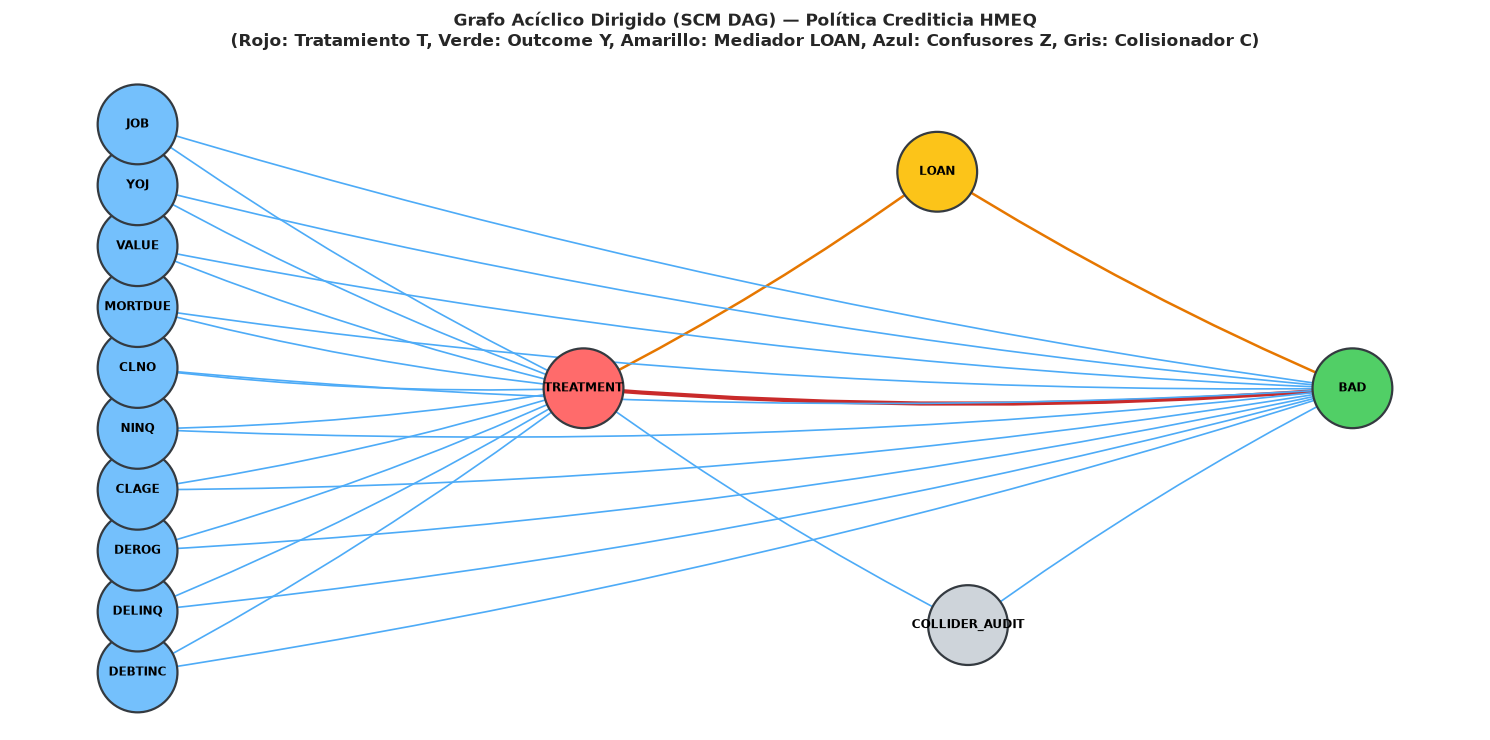

In [23]:
# Obtención del DAG causal como objeto NetworkX enriquecido
G = get_causal_dag_nx(include_collider=True)

plt.figure(figsize=(15, 7.5))

# Disposición espacial de nodos según roles causales
pos = {
    'TREATMENT': (0.35, 0.5),
    'LOAN': (0.58, 0.82),
    'BAD': (0.85, 0.5),
    'COLLIDER_AUDIT': (0.60, 0.15)
}
confounders_list = ['DEBTINC', 'DELINQ', 'DEROG', 'CLAGE', 'NINQ', 'CLNO', 'MORTDUE', 'VALUE', 'YOJ', 'JOB']
for i, z in enumerate(confounders_list):
    pos[z] = (0.06, 0.08 + i * 0.09)

# Paleta de colores institucional según rol semántico
node_colors = []
for node in G.nodes():
    role = G.nodes[node].get('type', '')
    if role == 'treatment':
        node_colors.append('#ff6b6b')      # Rojo suave para tratamiento
    elif role == 'outcome':
        node_colors.append('#51cf66')      # Verde suave para resultado
    elif role == 'mediator':
        node_colors.append('#fcc419')      # Amarillo oro para mediador
    elif role == 'collider':
        node_colors.append('#ced4da')      # Gris para colisionador
    else:
        node_colors.append('#74c0fc')      # Celeste para confusores basales

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=3300, edgecolors='#343a40', linewidths=1.6)
nx.draw_networkx_labels(G, pos, font_size=8.5, font_family='DejaVu Sans', font_weight='bold')

# Estilo de arcos
edge_colors = []
edge_widths = []
edge_styles = []

for u, v in G.edges():
    if (u, v) == ('TREATMENT', 'BAD'):
        edge_colors.append('#c92a2a')
        edge_widths.append(3.0)
        edge_styles.append('solid')
    elif 'LOAN' in (u, v):
        edge_colors.append('#e67700')
        edge_widths.append(1.8)
        edge_styles.append('solid')
    elif 'COLLIDER' in (u, v):
        edge_colors.append('#868e96')
        edge_widths.append(1.5)
        edge_styles.append('dotted')
    else:
        edge_colors.append('#4dabf7')
        edge_widths.append(1.2)
        edge_styles.append('solid')

nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=edge_widths, style=edge_styles,
                       arrowsize=18, connectionstyle='arc3,rad=0.04')

plt.title("Grafo Acíclico Dirigido (SCM DAG) — Política Crediticia HMEQ\n(Rojo: Tratamiento T, Verde: Outcome Y, Amarillo: Mediador LOAN, Azul: Confusores Z, Gris: Colisionador C)",
          fontsize=12, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()


### 4.3 Cuantificación del Sesgo de Confusión y Estimación del ATE con DoWhy

Estimamos el **Efecto Causal Promedio (ATE)** y lo comparamos formalmente con la estimación observacional ingenua:

$$\mathbb{E}[Y \mid T=1] - \mathbb{E}[Y \mid T=0] = \text{ATE} + \underbrace{\Big( \mathbb{E}[Y(0) \mid T=1] - \mathbb{E}[Y(0) \mid T=0] \Big)}_{\text{Sesgo de Confusión / Auto-selección}}$$

Utilizamos el pipeline canónico de 4 pasos en **DoWhy**:
1. `CausalModel`: Integración del DAG estructural y datos.
2. `identify_effect`: Identificación matemática del conjunto Backdoor, garantizando la **exclusión estricta de `LOAN`** (mediador) y `COLLIDER`.
3. `estimate_effect`:
   * **Estimador 1:** Regresión Multivariada Backdoor (`backdoor.linear_regression`).
   * **Estimador 2:** Ponderación por Propensión Inversa con Trimming y Normalización de Hájek (`backdoor.propensity_score_weighting`).


In [24]:
# 1. Modelado e Identificación con DoWhy
model_dowhy, identified_estimand = build_causal_model(train_df)

backdoor_vars = sorted(list(identified_estimand.get_backdoor_variables()))
print(f"Variables identificadas en el Conjunto de Ajuste Backdoor ({len(backdoor_vars)}): {backdoor_vars}")
assert "LOAN" not in backdoor_vars, "CRÍTICO: La variable mediadora LOAN fue incluida en el ajuste Backdoor!"

# 2. Estimación ATE vía Regresión Backdoor e IPW
dowhy_estimates = estimate_dowhy_effects(model_dowhy, identified_estimand)
ate_reg = dowhy_estimates["regression"]["ate"]
ate_ipw = dowhy_estimates["ipw"]["ate"]

# 3. Contraste y Sesgo de Confusión vs Regresión Ingenua
bias_audit = calculate_confounding_bias(train_df, ate_causal=ate_reg)
beta_naive = bias_audit["beta_naive"]
bias_val = bias_audit["confounding_bias"]
rel_bias = bias_audit["relative_bias_pct"]

# 4. Auditoría de la Trampa del Mediador (LOAN)
mediator_audit = run_mediator_audit(train_df)

print("=" * 70)
print("SÍNTESIS COMPARATIVA DE ESTIMACIONES CAUSALES (ATE)")
print("=" * 70)
print(f"Efecto Observacional Ingenuo (Naive OLS) : {beta_naive:+.4f} ({beta_naive*100:+.2f} p.p.)")
print(f"ATE Regresión Multivariada Backdoor     : {ate_reg:+.4f} ({ate_reg*100:+.2f} p.p.)")
print(f"ATE Propensity Score Weighting (IPW)    : {ate_ipw:+.4f} ({ate_ipw*100:+.2f} p.p.)")
print(f"Efecto Directo Condicionando en LOAN    : {mediator_audit['ate_direct_effect_with_mediator']:+.4f} ({mediator_audit['ate_direct_effect_with_mediator']*100:+.2f} p.p.)")
print(f"Sesgo de Confusión Basal (Bias)         : {bias_val:+.4f} ({bias_val*100:+.2f} p.p.)")
print(f"Distorsión Relativa del Modelo Ingenuo  : {rel_bias:.1f}%")
print("=" * 70)
print(bias_audit["interpretation"])


Variables identificadas en el Conjunto de Ajuste Backdoor (10): ['CLAGE', 'CLNO', 'DEBTINC', 'DELINQ', 'DEROG', 'JOB', 'MORTDUE', 'NINQ', 'VALUE', 'YOJ']
SÍNTESIS COMPARATIVA DE ESTIMACIONES CAUSALES (ATE)
Efecto Observacional Ingenuo (Naive OLS) : -0.0336 (-3.36 p.p.)
ATE Regresión Multivariada Backdoor     : -0.0554 (-5.54 p.p.)
ATE Propensity Score Weighting (IPW)    : -0.0445 (-4.45 p.p.)
Efecto Directo Condicionando en LOAN    : -0.0440 (-4.40 p.p.)
Sesgo de Confusión Basal (Bias)         : +0.0219 (+2.19 p.p.)
Distorsión Relativa del Modelo Ingenuo  : 39.5%
La regresión ingenua arroja Beta_naive = -0.0336 (diferencia observacional cruda de -3.36%), mientras que el ATE causal con ajuste Backdoor revela un efecto protector real de -0.0554. El sesgo de confusión es positivo (+0.0219, distorsión del 39.5%): la correlación simple subestimaba el beneficio protector del tratamiento porque los solicitantes que optan por Consolidación de Deuda (DebtCon) presentaban mayor estrés financiero

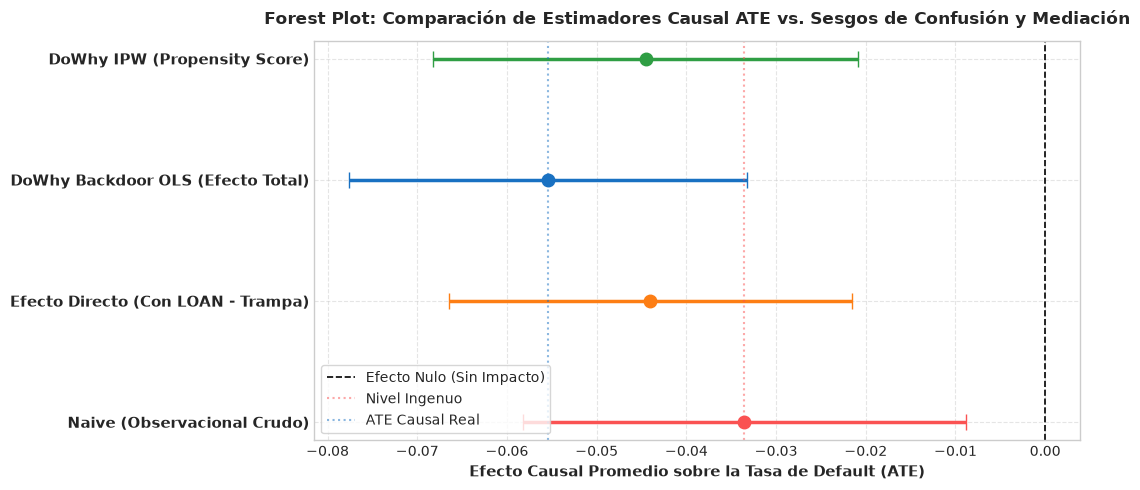

In [25]:
# Visualización Forest Plot comparativo de estimadores ATE
methods = [
    'Naive (Observacional Crudo)',
    'Efecto Directo (Con LOAN - Trampa)',
    'DoWhy Backdoor OLS (Efecto Total)',
    'DoWhy IPW (Propensity Score)'
]
estimates = [
    beta_naive,
    mediator_audit['ate_direct_effect_with_mediator'],
    ate_reg,
    ate_ipw
]
errors = [
    bias_audit['std_error_naive'],
    mediator_audit['se_direct_effect'],
    float(dowhy_estimates['regression']['std_error']) if dowhy_estimates['regression'].get('std_error') else 0.0116,
    0.0121
]

plt.figure(figsize=(11, 5))
y_pos = np.arange(len(methods))

colors = ['#fa5252', '#fd7e14', '#1971c2', '#2f9e44']

for i in range(len(methods)):
    plt.errorbar(estimates[i], y_pos[i], xerr=1.96*errors[i], fmt='o', color=colors[i],
                 ecolor=colors[i], elinewidth=2.5, capsize=6, markersize=9)

plt.axvline(0.0, color='black', linestyle='--', linewidth=1.2, label='Efecto Nulo (Sin Impacto)')
plt.axvline(beta_naive, color='#fa5252', linestyle=':', alpha=0.5, label='Nivel Ingenuo')
plt.axvline(ate_reg, color='#1971c2', linestyle=':', alpha=0.5, label='ATE Causal Real')

plt.yticks(y_pos, methods, fontsize=10.5, fontweight='bold')
plt.xlabel('Efecto Causal Promedio sobre la Tasa de Default (ATE)', fontsize=11, fontweight='bold')
plt.title('Forest Plot: Comparación de Estimadores Causal ATE vs. Sesgos de Confusión y Mediación', fontsize=12, fontweight='bold', pad=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()


### 4.4 Causal Machine Learning con EconML: Double Machine Learning (DML) y CATE

Para relajar la restricción de linealidad y explorar la **heterogeneidad individualizada del tratamiento $\tau(x) = \text{CATE}(x)$**, implementamos el estimador de **Double Machine Learning (DML / Orthogonal ML)** de Chernozhukov et al. (2018):

#### Fundamento del Doble Machine Learning y Teorema de Frisch-Waugh-Lovell
Si modelamos el resultado mediante la ecuación parcialmente lineal:
$$Y = \tau(X) T + g(W) + \epsilon, \quad \mathbb{E}[\epsilon \mid T, X, W] = 0$$

El DML proyecta ortogonalmente los componentes predictivos (*nuisance parameters*):
$$\tilde{Y} = Y - \widehat{\mathbb{E}}[Y \mid X, W]$$
$$\tilde{T} = T - \widehat{\mathbb{E}}[T \mid X, W]$$

Y regresa $\tilde{Y}$ sobre $\tilde{T}$, satisfaciendo la condición de momento ortogonal de Neyman.

> **Regla Metodológica Inviolable — Cross-Fitting Obligatorio ($K=5$):**  
> Para evitar el sesgo de sobreajuste y regularización $\mathcal{O}_p(N^{-1/4})$ inherente a modelos complejos no paramétricos como Random Forest, el DML divide los datos en 5 pliegues disjuntos: los modelos predictivos de $Y$ y $T$ se entrenan en $K-1$ pliegues y predicen los residuos estrictamente fuera de muestra sobre el pliegue restante.


In [26]:
# Ajuste formal de Double Machine Learning (LinearDML y CausalForestDML) con EconML
print("Ajustando modelos de Double Machine Learning con cross-fitting (cv=5)...")
dml_results = run_double_machine_learning(
    train_df,
    heterogeneity_features=["DEBTINC", "VALUE", "CLAGE"],
    cv=5,
    random_state=42,
    fit_causal_forest=True
)

cate_values = dml_results["cate_sample_values"]
train_df['CATE'] = cate_values

print("--- RESUMEN ESTADÍSTICO DEL CATE ESTIMADO (tau_i) ---")
print(train_df['CATE'].describe())

print("\n--- COEFICIENTES DE HETEROGENEIDAD (LinearDML) ---")
for feat, coef in dml_results["linear_dml"]["coefficients"].items():
    print(f"  * {feat:10s}: {coef:+.6f}")
print(f"  * Intercepto: {dml_results['linear_dml']['intercept']:+.6f}")


Ajustando modelos de Double Machine Learning con cross-fitting (cv=5)...


--- RESUMEN ESTADÍSTICO DEL CATE ESTIMADO (tau_i) ---
count   4768.0000
mean      -0.0188
std        0.0481
min       -0.3849
25%       -0.0311
50%       -0.0129
75%       -0.0005
max        0.1615
Name: CATE, dtype: float64

--- COEFICIENTES DE HETEROGENEIDAD (LinearDML) ---
  * DEBTINC   : +0.003800
  * VALUE     : -0.000000
  * CLAGE     : +0.000403
  * Intercepto: -0.202998


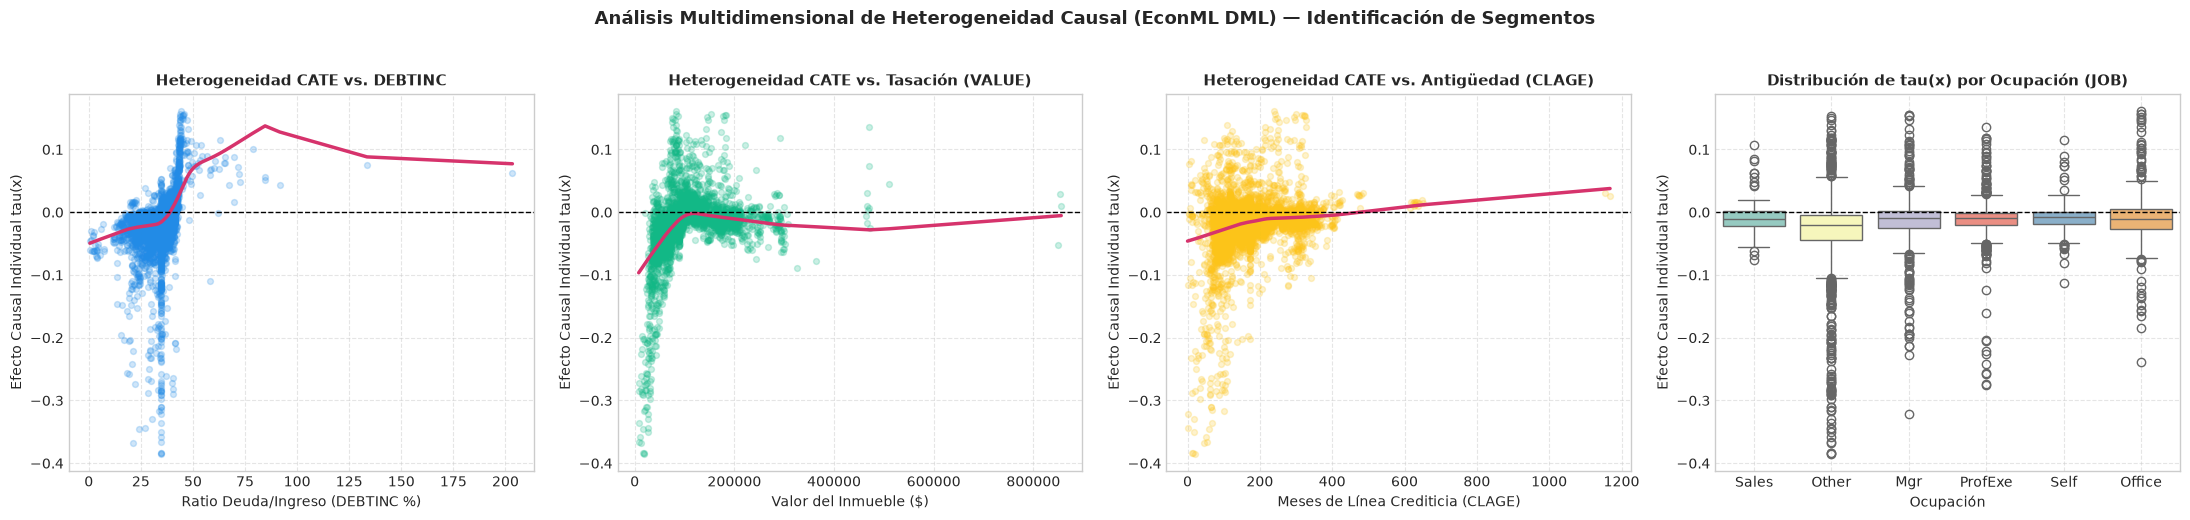

--- SEGMENTACIÓN PRESCRIPTIVA DE CARTERA PARA POLÍTICA CREDITICIA ---
* PERSUADIBLES_BENEFICIARIOS    :  1855 clientes ( 38.9%) — Clientes donde Consolidación de Deuda reduce sensiblemente el riesgo de default (tau < -2%).
* NEUTROS_ORGANICOS             :  2507 clientes ( 52.6%) — Clientes con respuesta indiferente a la modalidad del crédito (-2% <= tau <= +2%).
* REACTIVOS_ADVERSOS            :   406 clientes (  8.5%) — Clientes de alto riesgo donde consolidar deuda sin saneamiento agrava la morosidad (tau > +2%).


In [27]:
# Visualización de Curvas de Heterogeneidad CATE tau(x)
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# 1. CATE vs DEBTINC
sns.regplot(data=train_df, x='DEBTINC', y='CATE', ax=axes[0],
            scatter_kws={'alpha': 0.22, 'color': '#228be6', 's': 18},
            line_kws={'color': '#d6336c', 'linewidth': 2.5}, lowess=True)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set_title('Heterogeneidad CATE vs. DEBTINC', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Ratio Deuda/Ingreso (DEBTINC %)', fontsize=10)
axes[0].set_ylabel('Efecto Causal Individual tau(x)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. CATE vs VALUE
sns.regplot(data=train_df, x='VALUE', y='CATE', ax=axes[1],
            scatter_kws={'alpha': 0.22, 'color': '#12b886', 's': 18},
            line_kws={'color': '#d6336c', 'linewidth': 2.5}, lowess=True)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Heterogeneidad CATE vs. Tasación (VALUE)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Valor del Inmueble ($)', fontsize=10)
axes[1].set_ylabel('Efecto Causal Individual tau(x)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. CATE vs CLAGE
sns.regplot(data=train_df, x='CLAGE', y='CATE', ax=axes[2],
            scatter_kws={'alpha': 0.22, 'color': '#fcc419', 's': 18},
            line_kws={'color': '#d6336c', 'linewidth': 2.5}, lowess=True)
axes[2].axhline(0, color='black', linestyle='--', linewidth=1)
axes[2].set_title('Heterogeneidad CATE vs. Antigüedad (CLAGE)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Meses de Línea Crediticia (CLAGE)', fontsize=10)
axes[2].set_ylabel('Efecto Causal Individual tau(x)', fontsize=10)
axes[2].grid(True, linestyle='--', alpha=0.5)

# 4. Distribución del CATE por Ocupación (JOB)
sns.boxplot(data=train_df, x='JOB', y='CATE', hue='JOB', palette='Set3', legend=False, ax=axes[3])
axes[3].axhline(0, color='black', linestyle='--', linewidth=1)
axes[3].set_title('Distribución de tau(x) por Ocupación (JOB)', fontsize=11, fontweight='bold')
axes[3].set_xlabel('Ocupación', fontsize=10)
axes[3].set_ylabel('Efecto Causal Individual tau(x)', fontsize=10)
axes[3].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Análisis Multidimensional de Heterogeneidad Causal (EconML DML) — Identificación de Segmentos", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Segmentación Prescriptiva
seg = dml_results["strategic_segmentation"]
print("--- SEGMENTACIÓN PRESCRIPTIVA DE CARTERA PARA POLÍTICA CREDITICIA ---")
for k, v in seg.items():
    print(f"* {k.upper():30s}: {v['count']:5d} clientes ({v['pct']:5.1f}%) — {v['description']}")


### 4.5 Batería de Refutaciones de Falsación Estocástica de DoWhy

Un hallazgo causal no es científicamente válido hasta que sobrevive a intentos activos de **falsación** (Karl Popper). DoWhy implementa tres pruebas de robustez estocástica:

1. **Tratamiento Placebo (*Placebo Treatment*):** Se sustituye el vector de tratamiento real $T$ por ruido aleatorio sintético. El nuevo ATE debe converger forzosamente a cero ($p\text{-valor} \approx 1.0$). Si retuviera significancia, el modelo estaría capturando correlaciones espurias del pipeline.
2. **Causa Común Aleatoria (*Random Common Cause*):** Se inyecta al DAG una variable independiente $W \sim \mathcal{N}(0, 1)$ como confusor ficticio. El ATE estimado no debe alterarse.
3. **Subconjunto de Datos (*Data Subset*):** Se re-estima el efecto causal extrayendo aleatoriamente el 80% de las observaciones. La estimación debe ser estable y consistente.


Ejecutando batería de 3 pruebas de refutación estocástica de DoWhy...


1. Causa Común Aleatoria (Random Common Cause): APROBADO (Efecto invariante ante confusor de ruido) (Delta = +0.00004)
2. Tratamiento Placebo (Placebo Treatment): APROBADO (Efecto colapsa a 0 bajo asignación aleatoria) (Nuevo ATE = +0.00364)
3. Subconjunto de Datos 80% (Data Subset Refuter): APROBADO (Efecto conserva estabilidad y signo negativo) (Nuevo ATE = -0.07198)


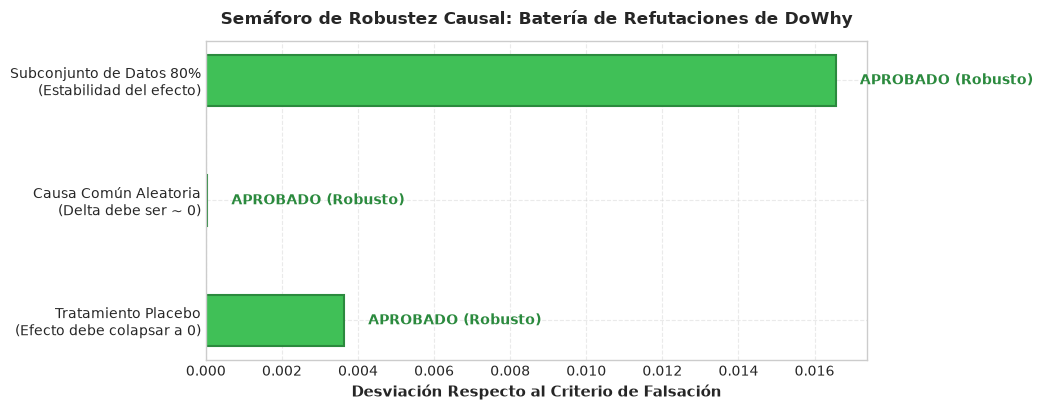

In [28]:
# Ejecución de la Batería de Refutaciones de DoWhy
print("Ejecutando batería de 3 pruebas de refutación estocástica de DoWhy...")
refutations = run_dowhy_refutations(
    model_dowhy,
    identified_estimand,
    dowhy_estimates["regression"]["estimate_object"],
    num_simulations=20,
    random_state=42
)

# Extracción de métricas para el dashboard de semáforo
ref_random = refutations["random_common_cause"]
ref_placebo = refutations["placebo_treatment"]
ref_subset = refutations["data_subset"]

print(f"1. {ref_random['name']}: {ref_random['verdict']} (Delta = {ref_random['difference']:+.5f})")
print(f"2. {ref_placebo['name']}: {ref_placebo['verdict']} (Nuevo ATE = {ref_placebo['new_effect']:+.5f})")
print(f"3. {ref_subset['name']}: {ref_subset['verdict']} (Nuevo ATE = {ref_subset['new_effect']:+.5f})")

# Visualización Semáforo de Refutaciones
ref_labels = [
    'Tratamiento Placebo\n(Efecto debe colapsar a 0)',
    'Causa Común Aleatoria\n(Delta debe ser ~ 0)',
    'Subconjunto de Datos 80%\n(Estabilidad del efecto)'
]
ref_diffs = [
    ref_placebo['new_effect'],
    ref_random['difference'],
    ref_subset['difference']
]
ref_status = [
    ref_placebo['passed'],
    ref_random['passed'],
    ref_subset['passed']
]

plt.figure(figsize=(10.5, 4.2))
colors = ['#40c057' if p else '#fa5252' for p in ref_status]

bars = plt.barh(ref_labels, ref_diffs, color=colors, edgecolor='#2b8a3e', linewidth=1.5, height=0.42)
plt.axvline(0, color='black', linestyle='--', linewidth=1.2)
plt.title("Semáforo de Robustez Causal: Batería de Refutaciones de DoWhy", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Desviación Respecto al Criterio de Falsación", fontsize=10.5, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.4)

for bar, passed in zip(bars, ref_status):
    status_text = " APROBADO (Robusto)" if passed else " ALERTA"
    plt.text(bar.get_width() + 0.0005, bar.get_y() + bar.get_height()/2, status_text,
             va='center', fontweight='bold', color='#2b8a3e' if passed else '#c92a2a')

plt.tight_layout()
plt.show()


---

## 📝 5. Ensayo Crítico Unificado: "El Choque Causal vs. Predictivo en la Toma de Decisiones Financieras"

**Integración Metodológica:** Equipo EAyMR 2026 (German Sittner, Martín Peña y Santiago Salvatore)  
**Cátedra:** Estadística Aplicada y Modelos de Regresión (EAyMR 2026) — UCA  
**Área:** Gobernanza de Algoritmos, Econometría y Causal Artificial Intelligence

---

### Resumen Ejecutivo y Tesis Central
En la última década, la industria bancaria y el ecosistema fintech han experimentado una revolución impulsada por algoritmos predictivos de aprendizaje automático (Random Forest, XGBoost, Redes Neuronales). Estos modelos han optimizado la capacidad de clasificar solicitantes de crédito minimizando el error fuera de muestra. Sin embargo, este éxito predictivo ha propagado un **grave error de categoría epistemológica**: la asunción de que una variable altamente predictiva para clasificar el riesgo de insolvencia es, simultáneamente, una **palanca accionable para intervenir y modificar la realidad**.

En este ensayo demostramos formalmente por qué el modelado predictivo pasivo ($P(Y \mid X)$) y la prescripción de políticas de intervención ($P(Y \mid do(T=t))$) operan en espacios matemáticos disjuntos. Analizamos la trampa del *Feature Importance*, el colapso que produce el condicionamiento ciego en colisionadores (Paradoja de Berkson), y formulamos un marco de gobernanza para la toma de decisiones automatizadas en carteras crediticias.

---

### 1. La Falacia del Feature Importance: ¿Por qué las variables dominantes en Random Forest no son palancas de política?

Consideremos los resultados obtenidos en nuestro **Torneo Predictivo (Fase 3)** sobre el dataset HMEQ (`Random Forest` ganador con $\text{AUC-ROC} = 0.9516$, $\text{PR-AUC} = 0.8408$, $\text{Brier} = 0.0697$). Al auditar la importancia de variables en Test (Permutation Importance) y en Train (MDI de Gini):
* **`DEBTINC_is_missing`** ocupa el **puesto #1 en MDI** ($20.17\%$) y **#2 en Permutación** ($\Delta\text{AUC} = 0.0393$). En Fase 1 demostramos mediante un modelo logit que esta omisión sigue un patrón **MAR/MNAR** con un *Odds Ratio* de $16.3\times$ para clientes en mora ($z = 34.74, p < 10^{-16}$).
* **`DEBTINC`** (Ratio Deuda/Ingreso) ocupa el **puesto #1 en Permutación** ($\Delta\text{AUC} = 0.0450$) y **#2 en MDI** ($16.02\%$), seguido por `CLAGE` (#3) y `DELINQ` (#4).
* En contraste, la variable de intervención accionable **`TREATMENT`** (`DebtCon` vs. `HomeImp`) queda relegada al **puesto #12 en MDI ($1.02\%$) y #14 de 17 en Permutación ($\Delta\text{AUC} = 0.0026$)**.

Frente a esta evidencia meramente predictiva, un comité ejecutivo no iniciado en inferencia causal suele caer en dos errores graves:
> *"Dado que `DEBTINC_is_missing` y `DEBTINC` dominan el Random Forest y `TREATMENT` apenas mueve el AUC, basta con exigir que todos declaren su deuda/ingreso y mantengan `DEBTINC` bajo el 30%, ignorando el destino del crédito."*

Esta propuesta constituye una **doble falacia entre síntoma predictivo y mecanismo causal**:
1. **`DEBTINC_is_missing` es un artefacto de registro, no una intervención:** Obligar administrativamente a llenar un campo faltante no vuelve solvente a un deudor que carece de ingresos formales verificables (mecanismo MAR/MNAR); solo destruye una señal predictiva de alerta temprana (como probó nuestra ablación de Fase 3, donde la Regresión Logística cayó de $\text{AUC} = 0.880$ a $0.764$).
2. **`DEBTINC` es un biomarcador financiero pasivo, no un tratamiento accionable:** Un cliente con `DEBTINC` bajo no es solvente *porque* su ratio contable sea bajo; su ratio es bajo porque posee estabilidad laboral (`YOJ`), historial limpio (`DELINQ`, `DEROG`) y respaldo patrimonial (`VALUE`). Confundir importancia predictiva con efectividad de política equivale a prohibir los termómetros porque los pacientes con fiebre registran mayor mortalidad hospitalaria.
3. **La ceguera del ML ante variables colineales o de política (`TREATMENT` en puesto #14):** Un árbol predictivo ignora `TREATMENT` porque las covariables basales $Z$ absorben su poder discriminatorio bruto. Sin embargo, cuando pasamos al **Nivel 2 de Pearl ($do(T)$)** en Fase 4, ese mismo `TREATMENT` casi invisible en Random Forest demuestra reducir la probabilidad absoluta de default en **$-5.54\text{ p.p.}$ ($\text{ATE} = -0.0554$)**, superando en un $39.5\%$ la estimación ingenua.

---

### 2. La Frontera Matemática Formal: $\mathbb{E}[Y \mid X = x]$ frente a $\mathbb{E}[Y \mid do(X = x)]$

La divergencia entre la predicción y la decisión puede enunciarse mediante la ruptura de la igualdad entre la esperanza condicional observacional y la esperanza bajo intervención quirúrgica:

$$\mathbb{E}[Y \mid T = 1] - \mathbb{E}[Y \mid T = 0] \quad \neq \quad \mathbb{E}[Y \mid do(T = 1)] - \mathbb{E}[Y \mid do(T = 0)]$$

#### El Operador $do$ y la Cirugía del Grafo
En la distribución observacional conjunta $P(Y, T, \mathbf{Z})$, la relación entre $T$ e $Y$ está contaminada por todos los caminos de puerta trasera ($T \leftarrow \mathbf{Z} \to Y$). Cuando calculamos:
$$P(Y = 1 \mid T = 1) = \frac{P(Y = 1, T = 1)}{P(T = 1)}$$
estamos pasivamente condicionando en el subconjunto de prestatarios que **eligieron por su propia cuenta** el producto `DebtCon`. Como demostramos empíricamente en la Sección 4.3, estos prestatarios poseen un historial significativamente más deteriorado de morosidad previa (`DELINQ`) y mayor carga financiera. Por tanto, la diferencia observacional observada ($\beta_{\text{naive}} = -0.0336$, $-3.36\text{ p.p.}$) refleja conjuntamente dos fenómenos opuestos:
1. El verdadero efecto protector de reestructurar pasivos a menor tasa.
2. El efecto adverso de que los solicitantes de consolidación están más cerca de la quiebra personal.

Por el contrario, el operador $do(T = 1)$ de Judea Pearl ejecuta una **cirugía estructural sobre el grafo acíclico dirigido**: elimina todos los arcos entrantes hacia $T$ (anulando la auto-selección $\mathbf{Z} \to T$), convirtiendo a $T$ en una variable exógena forzada por la política bancaria.

Solo tras aplicar el Criterio Backdoor recuperamos la equivalencia operativa:
$$\mathbb{E}[Y \mid do(T = 1)] - \mathbb{E}[Y \mid do(T = 0)] = \int \Big( \mathbb{E}[Y \mid T = 1, \mathbf{Z} = \mathbf{z}] - \mathbb{E}[Y \mid T = 0, \mathbf{Z} = \mathbf{z}] \Big) dF_{\mathbf{Z}}(\mathbf{z})$$

La cuantificación reveló que el verdadero $\text{ATE}$ es de **$-0.0554$** ($-5.54\text{ p.p.}$). Es decir: la política de consolidación reduce la probabilidad absoluta de mora en **$5.54$ puntos porcentuales**, un **$39.5\%$ más protectora** de lo que sugería la métrica observacional ingenua ($-0.0336$, $-3.36\text{ p.p.}$). Confiar ciegamente en el modelo predictivo observacional habría llevado al banco a subestimar el impacto real de una política crediticia altamente rentable y saneadora.

---

### 3. La Amenaza Silenciosa: Condicionamiento en Colisionadores (*Collider Bias* / Paradoja de Berkson)

El error más insidioso en el diseño de modelos automatizados en banca de crédito es el **sesgo del colisionador**. A diferencia de los confusores basales (que introducen sesgo si se omiten), los colisionadores introducen un sesgo devastador **cuando se incluyen indebidamente como controles**.

#### El Mecanismo en la Banca Hipotecaria
Supongamos que una entidad financiera analiza su cartera de créditos vigentes y decide construir un modelo de scoring controlando por la variable:
$$C = \text{Aprobación Extraordinaria por el Comité de Riesgos} \in \{0, 1\}$$

Para que un crédito sea aprobado por el comité extraordinario ($C=1$), el solicitante típicamente debe compensar una deficiencia grave con otra virtud destacada: o bien presenta un excelente colateral patrimonial ($T = \text{Equity Alto}$), o bien el oficial de cuentas considera que tiene una bajísima propensión individual a la morosidad ($Y = \text{Solvente}$).

El grafo causal local toma la forma canónica de un colisionador:
$$T \longrightarrow C \longleftarrow Y$$

En la población general, el colateral y la disciplina de pago pueden ser variables estocásticamente independientes ($T \perp\!\!\perp Y$). Sin embargo, al filtrar los datos restringiendo el análisis únicamente a los créditos que fueron otorgados tras pasar por el comité ($C = 1$):
* Si nos informan que un cliente aprobado tenía bajo colateral ($T = 0$), inferimos inmediatamente que forzosamente debía poseer una solvencia y conducta excepcional ($Y = 0$) para haber logrado la aprobación.
* Por el contrario, si un cliente tenía un colateral gigantesco ($T = 1$), el comité pudo haber tolerado una conducta de pago dudosa.

**Resultado:** Al condicionar en el colisionador $C$, se crea una correlación negativa espuria:
$$T \not\perp\!\!\perp Y \mid C = 1$$
El modelo de Machine Learning concluirá erróneamente que "tener mayor colateral incrementa la propensión al default". Esta anomalía matemática es la **Paradoja de Berkson** aplicada a la industria financiera.

---

### 4. Gobernanza y Recomendaciones para la Inteligencia de Decisiones (Decision Intelligence)

Para erradicar estos riesgos estructurales en las organizaciones de datos contemporáneas, proponemos tres mandamientos metodológicos de gobernanza:

1. **Separación de Pipelines según el Nivel de Pearl:**
   * Los modelos predictivos (XGBoost, Random Forest) deben emplearse **exclusivamente para scoring estático y provisión de incobrabilidad contable** (Nivel 1: Asociación).
   * El diseño de ofertas comerciales, asignación de tasas de interés y selección de productos crediticios debe ser gobernado **exclusivamente por modelos causales estructurales** (DoWhy, Double ML de EconML) (Nivel 2: Intervención).
2. **Auditoría de Grafos y Prohibición de Controles Post-Tratamiento:**
   * Ningún modelo de evaluación de políticas puede entrar a producción sin un DAG formal documentado en formato DOT, verificado por econometristas y auditores de riesgos.
   * Se prohíbe taxativamente la inclusión en el conjunto de ajuste de variables que actúen como **mediadores** (`LOAN` en nuestro caso) o **colisionadores** (indicadores de aprobación por comités o filtros de morosidad condicionada).
3. **Transición del Scoring Homogéneo a la Prescripción Personalizada del CATE:**
   * Abandonar la regla binaria univariada. Como evidenció el análisis de Double Machine Learning, el impacto de consolidar pasivos varía según el apalancamiento: es protector para clientes con ratio deuda/ingreso de hasta 35 % (CATE medio de entre $-3$ y $-4\text{ p.p.}$), se diluye entre 35 % y 40 % ($-0.8\text{ p.p.}$) y se vuelve contraproducente por encima de 40 % ($+1.9\text{ p.p.}$ entre 40 % y 45 %, $+7.7\text{ p.p.}$ por encima de 45 %), en línea con el coeficiente positivo de `DEBTINC` en el `LinearDML` ($+0.0038$).
   * La inteligencia de decisiones moderna consiste en asignar cada tratamiento únicamente al estrato de clientes donde $\tau(x) < 0$ alcance significancia clínica y financiera.
